<div><center><img src="https://ml.ucv.ai/logo.png" width="150"/></center></div>

# 05 Autoencoders y Stacked AutoEncoders

**Contenido**

1. Autoencoder: compresión, reconstrucción, *denoising* y qué aprende el cuello de botella
2. Stacked Autoencoders: preentrenamiento *greedy* capa por capa y *fine-tuning* (PyTorch)
3. El mismo experimento en Keras, paso a paso
4. Redes residuales (ResNet): la otra forma de entrenar redes profundas
5. Fine-tuning de un modelo preentrenado (ResNet18)
6. Transfer learning con Hugging Face: ResNet-50 y, con el mismo código, un ViT
7. Cierre: del stacked autoencoder de 2006 al preentrenamiento auto-supervisado de hoy

**Basado en**

- Hinton, G. E. & Salakhutdinov, R. R. (2006). *Reducing the dimensionality of data with neural networks*. Science, 313(5786). [doi:10.1126/science.1127647](https://doi.org/10.1126/science.1127647)
- Bengio, Y., Lamblin, P., Popovici, D. & Larochelle, H. (2007). *Greedy layer-wise training of deep networks*. NIPS 19.
- Vincent, P., Larochelle, H., Lajoie, I., Bengio, Y. & Manzagol, P.-A. (2010). *Stacked denoising autoencoders*. JMLR 11.
- He, K., Zhang, X., Ren, S. & Sun, J. (2016). *Deep residual learning for image recognition*. CVPR. [arXiv:1512.03385](https://arxiv.org/abs/1512.03385)
- He, K., Chen, X., Xie, S., Li, Y., Dollár, P. & Girshick, R. (2022). *Masked autoencoders are scalable vision learners*. CVPR. [arXiv:2111.06377](https://arxiv.org/abs/2111.06377)
- Géron, A. *Hands-On Machine Learning*, cap. 17 (Autoencoders).
- [Keras: Building Autoencoders](https://blog.keras.io/building-autoencoders-in-keras.html) y [Hugging Face: Fine-Tune ViT for Image Classification](https://huggingface.co/blog/fine-tune-vit)

En las secciones 1, 2, 4 y 5 usamos `PyTorch`; en la 3, `Keras`; en la 6, `transformers` de Hugging Face (sobre PyTorch). Ejecuten con GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*.

In [ ]:
!nvidia-smi

Tue Oct  6 13:07:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 1. **Autoencoder**

Un **autoencoder** es una red neuronal que aprende a reconstruir su entrada después de comprimirla en una representación latente de menor dimensión. Es aprendizaje **no supervisado** (o, mejor dicho, *auto-supervisado*): la etiqueta es la propia entrada.

Un autoencoder consta de dos partes:

- **Codificador (encoder)**:
  $$
  \mathbf{z} = f_{\theta}(\mathbf{x}) = \sigma(\mathbf{W}_e \mathbf{x} + \mathbf{b}_e)
  $$

- **Decodificador (decoder)**:
  $$
  \hat{\mathbf{x}} = g_{\phi}(\mathbf{z}) = \sigma'(\mathbf{W}_d \mathbf{z} + \mathbf{b}_d)
  $$

- **Función de pérdida** (error de reconstrucción):
  $$
  L(\mathbf{x}, \hat{\mathbf{x}}) = \| \mathbf{x} - \hat{\mathbf{x}} \|^2
  $$

## Tres cosas que conviene tener claras

1. **Cuello de botella.** Si $\dim(\mathbf{z}) < \dim(\mathbf{x})$ el autoencoder es *undercomplete*: no puede copiar la entrada y está obligado a quedarse con lo importante. Si $\dim(\mathbf{z}) \geq \dim(\mathbf{x})$ (*overcomplete*) hace falta otra restricción (ruido, dispersión, regularización) o aprende la identidad.
2. **Autoencoder lineal = PCA.** Con encoder y decoder lineales y pérdida MSE, el subespacio que aprende el autoencoder es el mismo de las componentes principales (Baldi & Hornik, 1989). La no linealidad es lo que permite ir más allá de PCA.
3. **La activación de salida depende del rango de los datos.** Nuestras imágenes están en $[0, 1]$, así que el decoder termina en una sigmoide. Si normalizáramos a $[-1, 1]$, una sigmoide nunca podría reconstruir los valores negativos (ojo con esto en la sección 2).

## Aplicaciones
- Reducción de dimensionalidad
- Filtrado y eliminación de ruido
- Detección de anomalías (error de reconstrucción alto = ejemplo raro)
- Preentrenamiento de redes profundas (sección 2)
- Generación de datos (autoencoder variacional, más adelante en el curso)

In [ ]:
import os, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

# MNIST, sin normalizar: los píxeles quedan en [0, 1]
transform = transforms.ToTensor()
train_data = datasets.MNIST(root="data", train=True,  download=True, transform=transform)
test_data  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# Subconjuntos fijos para que todo corra en segundos
num_train_samples, num_test_samples = 10000, 1000
g = torch.Generator().manual_seed(SEED)
train_indices = torch.randperm(len(train_data), generator=g)[:num_train_samples]
test_indices  = torch.randperm(len(test_data),  generator=g)[:num_test_samples]

train_subset_sampler = torch.utils.data.SubsetRandomSampler(train_indices)
test_subset_sampler  = torch.utils.data.SubsetRandomSampler(test_indices)

PyTorch 2.11.0+cu130 | dispositivo: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 525kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.1MB/s]


## Creación de dataloaders de entrenamiento y test

In [ ]:
batch_size = 32

train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, sampler=train_subset_sampler, num_workers=0)
test_loader  = torch.utils.data.DataLoader(test_data,  batch_size=batch_size, sampler=test_subset_sampler,  num_workers=0)

## Visualizar datos

In [ ]:
def f(params):
    for i in range(params[0]):
         l.append(g(i, params[1]))
    return l

def f_generador(params):
    for i in range(params[0]):
        yield g(i, params[1])


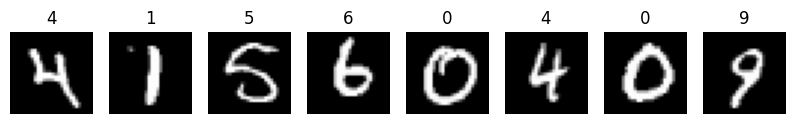

In [ ]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(10, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(images[k, 0], cmap="gray"); ax.set_title(int(labels[k])); ax.axis("off")
plt.show()

## Definición: Autoencoder lineal

- Las imágenes son de $28 \times 28$; con `flatten` se convierten en vectores de 784 dimensiones.
- Ya están en $[0, 1]$, así que la salida del decoder usa una **sigmoide**.
- `AutoencoderSimple` tiene una sola capa oculta; su único hiperparámetro es `encoding_dim`.
- `Autoencoder` tiene dos capas en cada lado: es un autoencoder *profundo* entrenado de una vez (lo contrastaremos con el entrenamiento capa por capa en la sección 2).

In [ ]:
class AutoencoderSimpleClase(nn.Module):
    def __init__(self, encoding_dim, x_dim=28*28):
        super().__init__()
        self.encoder = nn.Linear(x_dim, encoding_dim)
        self.decoder = nn.Linear(encoding_dim, x_dim)

    @staticmethod # PEP code style
    def activation(x, class_="relu"):
        if class_ == "relu":
            return F.relu(x)
        return torch.sigmoid(x)

    def encode(self, x):
        return F.relu(self.encoder(x))

    def decode(self, x):
        return torch.sigmoid(self.decoder(x))

    def forward(self, x):
        return self.decode(self.encode(x))

class AutoencoderSimple(nn.Module):
    def __init__(self, encoding_dim, x_dim=28*28):
        super().__init__()
        self.encoder = nn.Linear(x_dim, encoding_dim)
        self.decoder = nn.Linear(encoding_dim, x_dim)

    def encode(self, x):
        return F.relu(self.encoder(x))

    def forward(self, x):
        return torch.sigmoid(self.decoder(self.encode(x)))


class Autoencoder(nn.Module):
    def __init__(self, encoding_dims=(128, 64)):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, encoding_dims[0]),
            nn.ReLU(),
            nn.Linear(encoding_dims[0], encoding_dims[1]),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dims[1], encoding_dims[0]),
            nn.ReLU(),
            nn.Linear(encoding_dims[0], 28 * 28),
            nn.Sigmoid(),      # salida entre 0 y 1
        )

    def encode(self, x):
        return self.encoder(x)

    def forward(self, x):
        return self.decoder(self.encoder(x))

In [ ]:
MODEL = "Simple"

match MODEL:
    case "Simple":
        model = AutoencoderSimple(encoding_dim=32)
    case "Complex":
        model = Autoencoder(encoding_dims=(128, 64))

model = model.to(device)
print(model)
print("parámetros:", sum(p.numel() for p in model.parameters()))

AutoencoderSimple(
  (encoder): Linear(in_features=784, out_features=32, bias=True)
  (decoder): Linear(in_features=32, out_features=784, bias=True)
)
parámetros: 50992


Contemos nosotros los parámetros

In [ ]:
# Encoder, Decoder, bias_encoder, bias_decoder
784 * 32 + 32 * 784 + 784 + 32

50992

## Entrenando

Importante: como estamos trabajando sobre la *representación* de las imágenes, no necesitamos la salida `y`. La función `entrenar_autoencoder` la vamos a reutilizar varias veces en la clase.

In [ ]:
def entrenar_autoencoder(model, loader, n_epochs=20, lr=1e-3, verbose=True):
    '''Entrena `model` para reconstruir su entrada (MSE). Devuelve la pérdida promedio por época.'''
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    historial = []
    model.train()
    for epoch in range(n_epochs):
        train_loss, n = 0.0, 0
        for images, _ in loader:                                    # las etiquetas no se usan
            images = images.view(images.size(0), -1).to(device)      # aplanar y mover a GPU
            optimizer.zero_grad()
            # Forward pass
            outputs = model(images)
            # Cálculo de la función de pérdida
            loss = criterion(outputs, images)                        # reconstrucción vs. entrada
            # Paso hacia atrás
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0); n += images.size(0)
        historial.append(train_loss / n)                            # promedio por ejemplo
        if verbose:
            print(f"Época {epoch + 1:2d}  L(θ) = {historial[-1]:.6f}")
    return historial

historial = entrenar_autoencoder(model, train_loader, n_epochs=20)

Época  1  L(θ) = 0.075777
Época  2  L(θ) = 0.044134
Época  3  L(θ) = 0.035444
Época  4  L(θ) = 0.030770
Época  5  L(θ) = 0.027657
Época  6  L(θ) = 0.025570
Época  7  L(θ) = 0.024131
Época  8  L(θ) = 0.023085
Época  9  L(θ) = 0.022249
Época 10  L(θ) = 0.021584
Época 11  L(θ) = 0.021074
Época 12  L(θ) = 0.020649
Época 13  L(θ) = 0.020311
Época 14  L(θ) = 0.020063
Época 15  L(θ) = 0.019870
Época 16  L(θ) = 0.019702
Época 17  L(θ) = 0.019549
Época 18  L(θ) = 0.019454
Época 19  L(θ) = 0.019364
Época 20  L(θ) = 0.019302


## Evaluación en el conjunto de prueba

Evaluamos la reconstrucción sobre imágenes que la red no vio y graficamos originales contra reconstrucciones.

In [ ]:
# Investigar cómo se llaman "las etiquetas que comienzan con arroba" DECORATORS g(perdida_test(x))
# def x():
# NO ESTAMOS ENTRANDO -> mejoras en rendimiento a la hora  del paso hacia adelante

@torch.no_grad()
def perdida_test(model, loader):
    model.eval()
    criterion = nn.MSELoss()
    total, n = 0.0, 0
    for images, _ in loader:
        images = images.view(images.size(0), -1).to(device)
        total += criterion(model(images), images).item() * images.size(0); n += images.size(0)
    return total / n

print(f"Pérdida en prueba: {perdida_test(model, test_loader):.6f}")

Pérdida en prueba: 0.018934


In [ ]:
@torch.no_grad()
def mostrar_reconstrucciones(model, images, n=10, titulo=None):
    '''Fila superior: originales; fila inferior: reconstrucciones.'''
    # Modelo en modalidad inferencia
    model.eval()
    # Mi vector de imágenes de dimensión n tiene en su componente k un vector de dimensión 784
    x = images[:n].view(n, -1).to(device)
    # Movemos los datos a CPU.
    salida = model(x).view(n, 28, 28).cpu()

    fig, axes = plt.subplots(2, n, figsize=(1.6 * n, 3.4))
    for k in range(n):
        # graficamos la imagen original
        axes[0, k].imshow(images[k, 0], cmap="gray"); axes[0, k].axis("off")
        # Graficamos la reconstrucción (dada la imagen original -> d(e(x)))
        axes[1, k].imshow(salida[k], cmap="gray");    axes[1, k].axis("off")
    axes[0, 0].set_title("original", loc="left", fontsize=9); axes[1, 0].set_title("reconstrucción", loc="left", fontsize=9)
    if titulo: fig.suptitle(titulo)
    plt.show()

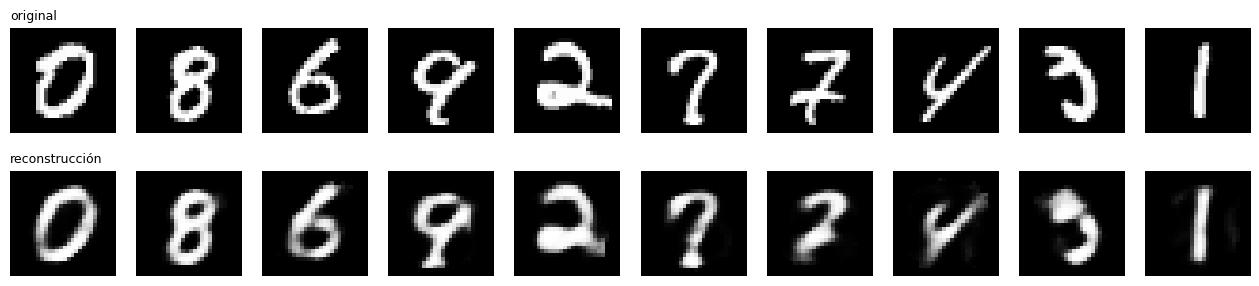

In [ ]:


test_images, test_labels = next(iter(test_loader))
mostrar_reconstrucciones(model, test_images)

## Aplicación: denoising!

Le agregamos ruido gaussiano a las imágenes de prueba y las pasamos por el autoencoder **que nunca vio ruido**. Fíjense en los dos MSE: el autoencoder reconstruye algo más parecido al original que la propia imagen ruidosa, porque solo puede producir cosas que viven en su espacio latente de 32 dimensiones. Un *denoising autoencoder* (Vincent et al., 2008) va un paso más allá: se entrena con entradas ruidosas y objetivo limpio.

MSE original vs. con ruido:     0.046044
MSE original vs. reconstruida:  0.033681


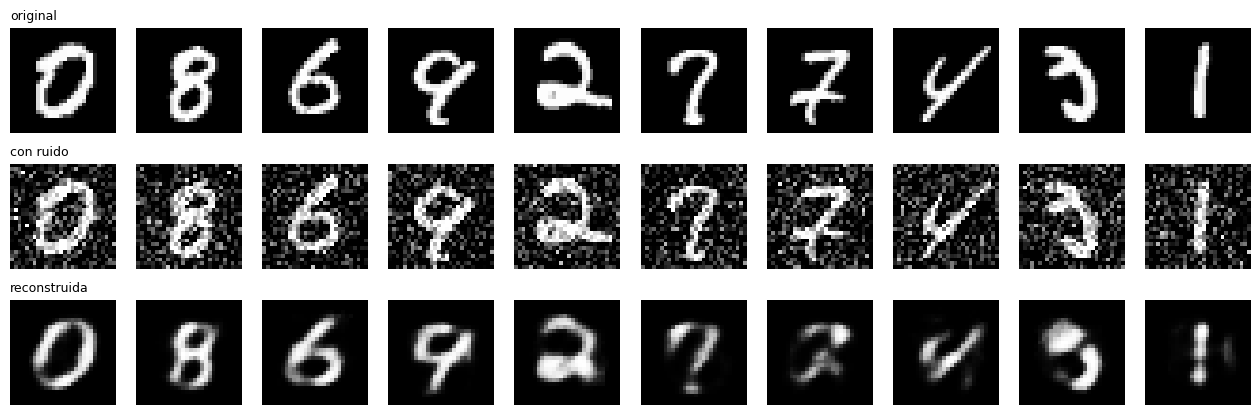

In [ ]:
torch.manual_seed(0)
x = test_images.view(test_images.size(0), -1)
x_ruido = torch.clamp(x + 0.3 * torch.randn_like(x), 0., 1.)

model.eval()
with torch.no_grad():
    x_rec = model(x_ruido.to(device)).cpu()

print(f"MSE original vs. con ruido:     {F.mse_loss(x_ruido, x).item():.6f}")
print(f"MSE original vs. reconstruida:  {F.mse_loss(x_rec, x).item():.6f}")

n = 10
fig, axes = plt.subplots(3, n, figsize=(1.6 * n, 5))
for k in range(n):
    for fila, (img, nombre) in enumerate([(x[k], "original"), (x_ruido[k], "con ruido"), (x_rec[k], "reconstruida")]):
        axes[fila, k].imshow(img.view(28, 28), cmap="gray"); axes[fila, k].axis("off")
        if k == 0: axes[fila, k].set_title(nombre, loc="left", fontsize=9)
plt.show()

## Qué aprende el cuello de botella?

Entrenamos un autoencoder con un espacio latente de **2 dimensiones** solo para poder dibujarlo. Cada punto es una imagen de prueba, el color es el dígito. Noten que la red nunca vio las etiquetas y aun así los dígitos tienden a agruparse: la representación que sirve para reconstruir también sirve, en parte, para clasificar. Esa es la intuición detrás del preentrenamiento de la sección 2.

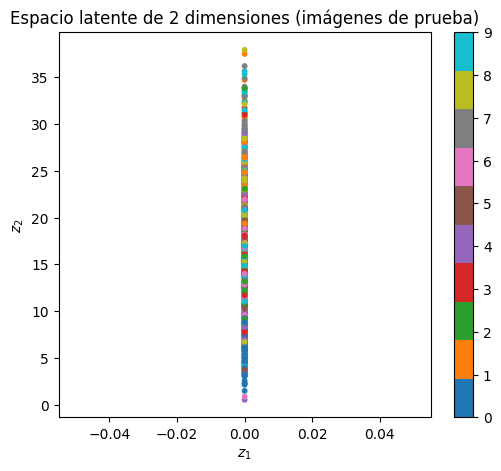

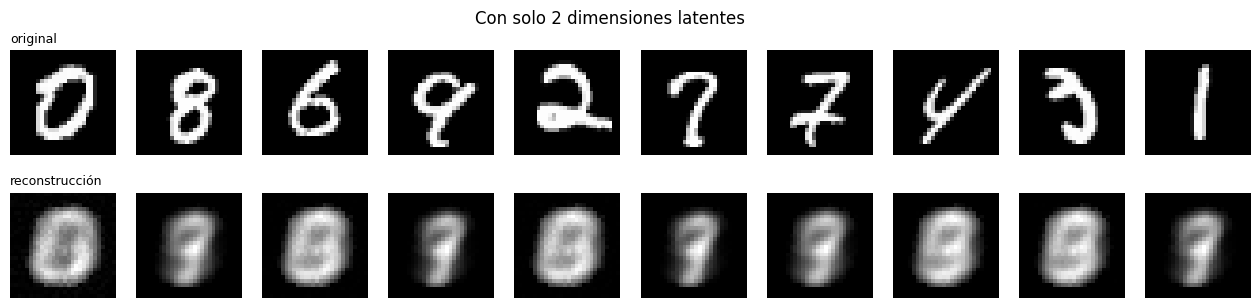

In [ ]:
torch.manual_seed(SEED)
ae2 = AutoencoderSimple(encoding_dim=2).to(device)
_ = entrenar_autoencoder(ae2, train_loader, n_epochs=15, verbose=False)

zs, ys = [], []
ae2.eval()
with torch.no_grad():
    for images, labels in test_loader:
        zs.append(ae2.encode(images.view(images.size(0), -1).to(device)).cpu()); ys.append(labels)
zs, ys = torch.cat(zs).numpy(), torch.cat(ys).numpy()

plt.figure(figsize=(6, 5))
sc = plt.scatter(zs[:, 0], zs[:, 1], c=ys, cmap="tab10", s=10)
plt.colorbar(sc, ticks=range(10)); plt.xlabel("$z_1$"); plt.ylabel("$z_2$"); plt.title("Espacio latente de 2 dimensiones (imágenes de prueba)")
plt.show()
mostrar_reconstrucciones(ae2, test_images, titulo="Con solo 2 dimensiones latentes")

# 2. **Stacked Autoencoders**

Los **stacked autoencoders** se construyen apilando varios autoencoders: la salida del codificador anterior alimenta al siguiente.

## Estructura del ejemplo

- Primer codificador:
  $$
  \mathbf{z}^{(1)} = \sigma(\mathbf{W}^{(1)} \mathbf{x} + \mathbf{b}^{(1)})
  $$

- Segundo codificador:
  $$
  \mathbf{z}^{(2)} = \sigma(\mathbf{W}^{(2)} \mathbf{z}^{(1)} + \mathbf{b}^{(2)})
  $$

- Primer decodificador:
  $$
  \hat{\mathbf{z}}^{(1)} = \sigma'(\mathbf{W}'^{(2)} \mathbf{z}^{(2)} + \mathbf{b}'^{(2)})
  $$

- Segundo decodificador:
  $$
  \hat{\mathbf{x}} = \sigma'(\mathbf{W}'^{(1)} \hat{\mathbf{z}}^{(1)} + \mathbf{b}'^{(1)})
  $$

En la formulación original los pesos del decoder son los del encoder transpuestos, $\mathbf{W}' = \mathbf{W}^{T}$ (*tied weights*, la mitad de parámetros). Nosotros los dejamos libres, que es lo más común hoy.

## Por qué existieron: un poco de historia

En 2006 no se podía entrenar una red de 4 o 5 capas de sigmoides desde cero: los gradientes se desvanecían (recuerden la clase de inicialización) y no existían ni ReLU, ni He, ni *batch norm*, ni conexiones residuales. Hinton y Salakhutdinov (2006) mostraron que sí se podía si la red se **preentrenaba capa por capa** sin etiquetas y luego se **ajustaba completa** (*fine-tuning*). Bengio et al. (2007) demostraron que la receta funciona también con autoencoders, y Vincent et al. (2010) que mejora si cada capa aprende a *quitar ruido* (stacked denoising autoencoders). Fue el arranque del *deep learning* moderno.

## Entrenamiento: tres fases

1. **Preentrenamiento *greedy* capa por capa.** Se entrena el autoencoder 1 para reconstruir $\mathbf{x}$. Se congela, se codifican todos los datos con él, y con esos códigos se entrena el autoencoder 2 para reconstruir $\mathbf{z}^{(1)}$. Y así sucesivamente. Cada capa es un problema poco profundo y fácil de optimizar.
2. **Desenrollado (*unrolling*).** Se apilan los encoders (y si queremos reconstruir los decoders en orden inverso). Si el objetivo es clasificar, se reemplazan los decoders por una capa de salida.
3. ***Fine-tuning*.** Se entrena la red completa con la tarea final (por ejemplo, entropía cruzada con las etiquetas). Los pesos preentrenados son una buena inicialización: la red arranca desde una representación útil en vez de desde el azar.

La celda siguiente dibuja el esquema (es nuestro propio dibujo; la figura original es la Fig. 1 de Hinton & Salakhutdinov, 2006, enlazada arriba).

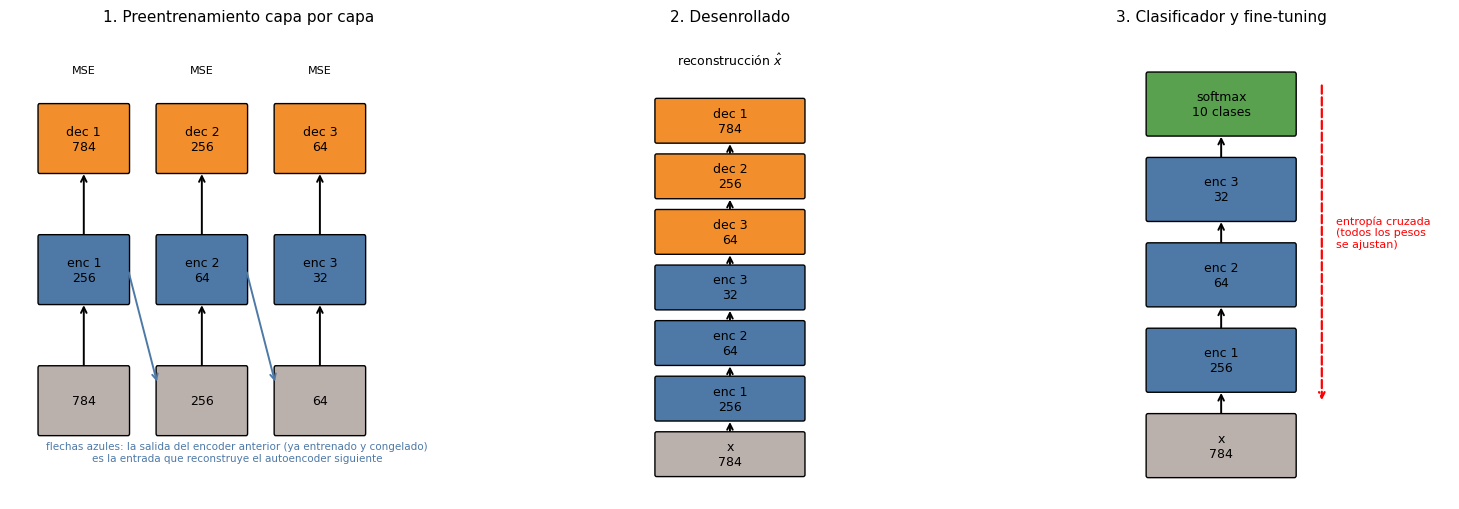

In [ ]:
def dibujar_esquema_sae(dims=(784, 256, 64, 32), n_clases=10):
    '''Esquema de las tres fases: preentrenamiento capa por capa, desenrollado y fine-tuning.'''
    import matplotlib.patches as mpatches
    azul, naranja, verde, gris = "#4e79a7", "#f28e2b", "#59a14f", "#bab0ac"
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))

    def caja(ax, x, y, w, h, color, texto, alpha=1.0):
        ax.add_patch(mpatches.FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02", fc=color, ec="black", alpha=alpha))
        ax.text(x, y, texto, ha="center", va="center", fontsize=9)

    def flecha(ax, x0, y0, x1, y1, color="black"):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=color, lw=1.4))

    # Fase 1: cada autoencoder por separado
    ax = axes[0]; ax.set_title("1. Preentrenamiento capa por capa", fontsize=11)
    for i in range(1, len(dims)):
        x = 1.6 * i
        caja(ax, x, 1.0, 1.2, 0.6, gris,    f"{dims[i-1]}")
        caja(ax, x, 2.2, 1.2, 0.6, azul,    f"enc {i}\n{dims[i]}")
        caja(ax, x, 3.4, 1.2, 0.6, naranja, f"dec {i}\n{dims[i-1]}")
        flecha(ax, x, 1.3, x, 1.9); flecha(ax, x, 2.5, x, 3.1)
        ax.text(x, 4.0, "MSE", ha="center", fontsize=8)
        if i > 1:
            flecha(ax, x - 1.0, 2.2, x - 0.6, 1.15, color=azul)
    ax.text(0.8 * (len(dims) + 0.6), 0.45, "flechas azules: la salida del encoder anterior (ya entrenado y congelado)\nes la entrada que reconstruye el autoencoder siguiente",
            ha="center", fontsize=7.5, color=azul)
    ax.set_xlim(0.6, 1.6 * len(dims) + 0.4); ax.set_ylim(0.1, 4.4); ax.axis("off")

    #  Fase 2: Unrolling (autoencoder profundo)
    ax = axes[1]; ax.set_title("2. Desenrollado", fontsize=11)
    capas = [f"x\n{dims[0]}"] + [f"enc {i}\n{dims[i]}" for i in range(1, len(dims))] + [f"dec {i}\n{dims[i-1]}" for i in range(len(dims) - 1, 0, -1)]
    colores = [gris] + [azul] * (len(dims) - 1) + [naranja] * (len(dims) - 1)
    for k, (c, col) in enumerate(zip(capas, colores)):
        caja(ax, 2.5, 0.5 + 0.62 * k, 1.6, 0.46, col, c)
        if k: flecha(ax, 2.5, 0.5 + 0.62 * (k - 1) + 0.23, 2.5, 0.5 + 0.62 * k - 0.23)
    ax.text(2.5, 0.5 + 0.62 * len(capas), "reconstrucción $\\hat{x}$", ha="center", fontsize=9)
    ax.set_xlim(0, 5); ax.set_ylim(0, 0.62 * len(capas) + 0.9); ax.axis("off")

    # Fase 3: clasificador + fine-tuning
    ax = axes[2]; ax.set_title("3. Clasificador y fine-tuning", fontsize=11)
    capas = [f"x\n{dims[0]}"] + [f"enc {i}\n{dims[i]}" for i in range(1, len(dims))] + [f"softmax\n{n_clases} clases"]
    colores = [gris] + [azul] * (len(dims) - 1) + [verde]
    for k, (c, col) in enumerate(zip(capas, colores)):
        caja(ax, 2.5, 0.5 + 0.8 * k, 1.6, 0.56, col, c)
        if k: flecha(ax, 2.5, 0.5 + 0.8 * (k - 1) + 0.28, 2.5, 0.5 + 0.8 * k - 0.28)
    ax.annotate("", xy=(3.6, 0.9), xytext=(3.6, 0.5 + 0.8 * len(capas) - 0.6), arrowprops=dict(arrowstyle="->", color="red", lw=1.6, ls="--"))
    ax.text(3.75, 0.5 + 0.4 * len(capas), "entropía cruzada\n(todos los pesos\nse ajustan)", color="red", fontsize=8, va="center")
    ax.set_xlim(0, 5); ax.set_ylim(0, 0.8 * len(capas) + 0.4); ax.axis("off")
    plt.tight_layout(); plt.show()

dibujar_esquema_sae()

## Datos para esta sección

Volvemos a cargar MNIST en subconjuntos fijos. Dos detalles que importan:

- **Sin normalizar a $[-1, 1]$**: nuestros decoders terminan en sigmoide, así que la entrada tiene que estar en $[0, 1]$. (Versiones anteriores de este notebook normalizaban con media 0.5 y desviación 0.5: el primer autoencoder nunca podía reconstruir los valores negativos.)
- Preparamos **dos conjuntos de entrenamiento**: uno grande *sin usar etiquetas* para preentrenar (6 000 imágenes) y uno pequeño *con etiquetas* (1 000 imágenes) para la clasificación. Así simulamos el escenario donde el preentrenamiento brilla: muchos datos sin etiquetar, pocos etiquetados.

In [ ]:
def get_mnist_loader(batch_size=128, num_train_samples=6000, num_test_samples=1000, seed=0):
    '''Devuelve (train_loader, test_loader) con subconjuntos fijos de MNIST, píxeles en [0, 1].'''
    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root="data", train=True,  transform=transform, download=True)
    test_dataset  = datasets.MNIST(root="data", train=False, transform=transform, download=True)
    g = torch.Generator().manual_seed(seed)
    train_indices = torch.randperm(len(train_dataset), generator=g)[:num_train_samples]
    test_indices  = torch.randperm(len(test_dataset),  generator=g)[:num_test_samples]
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, sampler=torch.utils.data.SubsetRandomSampler(train_indices))
    test_loader  = torch.utils.data.DataLoader(test_dataset,  batch_size=batch_size, sampler=torch.utils.data.SubsetRandomSampler(test_indices))
    return train_loader, test_loader

batch_size = 128
pretrain_loader, test_loader = get_mnist_loader(batch_size=batch_size, num_train_samples=6000, num_test_samples=1000)   # sin etiquetas
labeled_loader, _            = get_mnist_loader(batch_size=batch_size, num_train_samples=1000, seed=1)                   # con etiquetas (pocas)

## Proceso para escribir nuestro Stacked Autoencoder

Primero definimos el bloque de construcción, `AutoEncoderLayer`: un autoencoder de una capa con `encode`, `decode` y `forward` (= reconstrucción). Usamos sigmoide en el encoder, como en los trabajos originales, para que la salida de cada capa esté también en $[0, 1]$ y la capa siguiente pueda reconstruirla con otra sigmoide.

In [ ]:
class AutoEncoderLayer(nn.Module):
    '''Autoencoder de una capa: bloque de construcción del Stacked Autoencoder.'''
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.in_features, self.out_features = input_dim, hidden_dim
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Sigmoid())
        self.decoder = nn.Sequential(nn.Linear(hidden_dim, input_dim), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        return self.decode(self.encode(x))

    def congelar(self, congelado=True):
        for p in self.parameters():
            p.requires_grad = not congelado

## El preentrenamiento de cada capa

Fíjense en la idea: para entrenar la capa $i$, pasamos cada batch por los encoders $1, \ldots, i-1$ **sin gradiente** (están congelados: ya aprendieron) y la capa $i$ aprende a reconstruir *ese* código. La capa 1 reconstruye la imagen; la capa 2 reconstruye el código de 256 dimensiones; la capa 3, el de 64.

In [ ]:
def pretrain_layer(layers, i, loader, epochs=10, lr=1e-3):
    '''Preentrenamiento greedy: entrena layers[i] a reconstruir la salida de los encoders 0..i-1 (congelados).'''
    for l in layers[:i]:
        l.congelar(True); l.eval()
    layers[i].congelar(False); layers[i].train()
    optimizer = torch.optim.Adam(layers[i].parameters(), lr=lr)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        total, n = 0.0, 0
        for images, _ in loader:
            x = images.view(images.size(0), -1).to(device)
            with torch.no_grad():                    # paso hacia adelante por las capas ya entrenadas
                for l in layers[:i]:
                    x = l.encode(x)
            optimizer.zero_grad()
            loss = criterion(layers[i](x), x)        # la capa i reconstruye su propia entrada
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0); n += x.size(0)
        print(f"  capa {i + 1} ({layers[i].in_features} → {layers[i].out_features})  época {epoch + 1:2d}/{epochs}  L(θ) = {total / n:.5f}")

## Construir el StackedAutoEncoder

Conectamos los encoders de cada `AutoEncoderLayer` y agregamos la capa de clasificación. El método `reconstruir` recorre todos los encoders y luego los decoders en orden inverso: es el autoencoder *desenrollado* de la fase 2.

In [ ]:
class StackedAutoEncoderClassifier(nn.Module):
    '''Apila los encoders preentrenados y agrega una capa de clasificación.'''
    def __init__(self, autoencoder_list, num_classes=10):
        super().__init__()
        self.autoencoders = nn.ModuleList(autoencoder_list)
        self.classification_layer = nn.Linear(autoencoder_list[-1].out_features, num_classes)

    def encode(self, x):
        for ae in self.autoencoders:
            x = ae.encode(x)
        return x

    def reconstruir(self, x):
        z = self.encode(x)
        for ae in reversed(self.autoencoders):
            z = ae.decode(z)
        return z

    def forward(self, x):
        return self.classification_layer(self.encode(x))

    def congelar_encoders(self, congelado=True):
        for ae in self.autoencoders:
            ae.congelar(congelado)

## Entrenamiento del clasificador

`train_classifier` recibe qué parte de la red se entrena: `"head"` (solo la capa de clasificación, encoders congelados: *feature extraction*) o `"all"` (*fine-tuning* de la red completa, normalmente con una tasa de aprendizaje menor). Noten que el optimizador recibe **solo** los parámetros entrenables: en la versión anterior de este notebook recibía todos, así que "sin fine-tuning" entrenaba más de lo que decía.

In [ ]:
@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for images, labels in loader:
        x, y = images.view(images.size(0), -1).to(device), labels.to(device)
        correct += (model(x).argmax(1) == y).sum().item(); total += y.size(0)
    return correct / total


def train_classifier(model, loader, test_loader, epochs=20, lr=1e-3, trainable="all", verbose=True):
    '''trainable = "head": solo la capa de clasificación (encoders congelados); "all": fine-tuning completo.'''
    model.to(device)
    if trainable == "head":
        model.congelar_encoders(True)
        params = model.classification_layer.parameters()
    else:
        model.congelar_encoders(False)
        params = model.parameters()
    optimizer = torch.optim.Adam(params, lr=lr)
    criterion = nn.CrossEntropyLoss()
    hist = {"loss": [], "acc_test": []}
    for epoch in range(epochs):
        model.train()
        total, n = 0.0, 0
        for images, labels in loader:
            x, y = images.view(images.size(0), -1).to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0); n += x.size(0)
        hist["loss"].append(total / n); hist["acc_test"].append(accuracy(model, test_loader))
        if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
            print(f"  [{trainable}] época {epoch + 1:2d}/{epochs}  L(θ) = {hist['loss'][-1]:.4f}  acc test = {hist['acc_test'][-1]:.4f}")
    return hist

## Entrenamiento

Los hiperparámetros de épocas se dividen en tres:

1. Épocas de preentrenamiento por capa (sin etiquetas, 6 000 imágenes)
2. Épocas del clasificador con encoders congelados (con etiquetas, 1 000 imágenes)
3. Épocas de fine-tuning (con etiquetas, 1 000 imágenes)

In [ ]:
num_layer_wise_epochs  = 10
num_classifier_epochs  = 20
num_finetuning_epochs  = 20
dims = [784, 256, 64, 32]

### Fase 1: preentrenar los AutoEncoders

In [ ]:
torch.manual_seed(SEED)
encoders_list = [AutoEncoderLayer(dims[i], dims[i + 1]).to(device) for i in range(len(dims) - 1)]

for level in range(len(encoders_list)):
    pretrain_layer(encoders_list, level, pretrain_loader, epochs=num_layer_wise_epochs)

  capa 1 (784 → 256)  época  1/10  L(θ) = 0.08810
  capa 1 (784 → 256)  época  2/10  L(θ) = 0.06393
  capa 1 (784 → 256)  época  3/10  L(θ) = 0.05541
  capa 1 (784 → 256)  época  4/10  L(θ) = 0.04743
  capa 1 (784 → 256)  época  5/10  L(θ) = 0.04193
  capa 1 (784 → 256)  época  6/10  L(θ) = 0.03783
  capa 1 (784 → 256)  época  7/10  L(θ) = 0.03432
  capa 1 (784 → 256)  época  8/10  L(θ) = 0.03131
  capa 1 (784 → 256)  época  9/10  L(θ) = 0.02873
  capa 1 (784 → 256)  época 10/10  L(θ) = 0.02650
  capa 2 (256 → 64)  época  1/10  L(θ) = 0.09822
  capa 2 (256 → 64)  época  2/10  L(θ) = 0.08578
  capa 2 (256 → 64)  época  3/10  L(θ) = 0.06882
  capa 2 (256 → 64)  época  4/10  L(θ) = 0.05400
  capa 2 (256 → 64)  época  5/10  L(θ) = 0.04412
  capa 2 (256 → 64)  época  6/10  L(θ) = 0.03714
  capa 2 (256 → 64)  época  7/10  L(θ) = 0.03189
  capa 2 (256 → 64)  época  8/10  L(θ) = 0.02774
  capa 2 (256 → 64)  época  9/10  L(θ) = 0.02433
  capa 2 (256 → 64)  época 10/10  L(θ) = 0.02157
  capa 3 (

### Qué aprendió la primera capa?

Cada fila de $\mathbf{W}^{(1)}$ tiene 784 pesos: la podemos dibujar como una imagen de $28 \times 28$. Son los "detectores" que la capa 1 aprendió **sin ninguna etiqueta**. Comparen con los de una capa recién inicializada al azar.

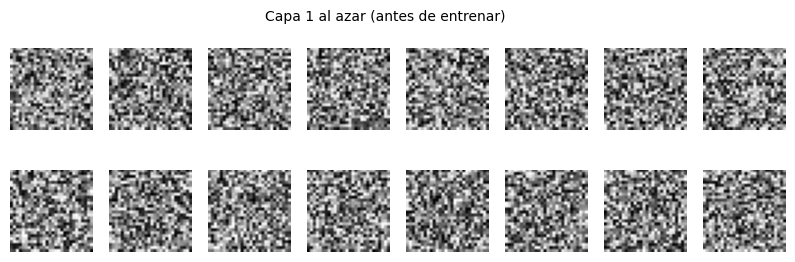

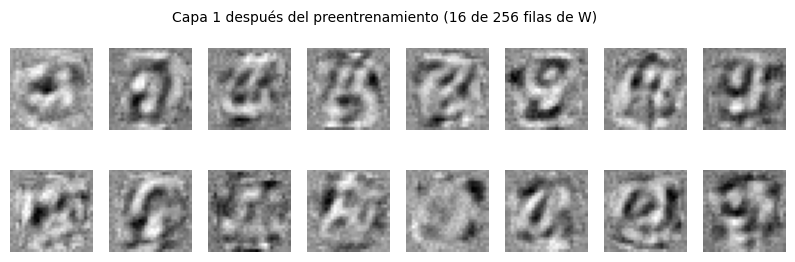

In [ ]:
def mostrar_filtros(W, n=16, titulo=""):
    W = W.detach().cpu()
    fig, axes = plt.subplots(2, n // 2, figsize=(1.3 * n // 2, 2.9))
    for k, ax in enumerate(axes.ravel()):
        ax.imshow(W[k].view(28, 28), cmap="gray"); ax.axis("off")
    fig.suptitle(titulo, fontsize=10); plt.show()

mostrar_filtros(AutoEncoderLayer(784, 256).encoder[0].weight, titulo="Capa 1 al azar (antes de entrenar)")
mostrar_filtros(encoders_list[0].encoder[0].weight, titulo="Capa 1 después del preentrenamiento (16 de 256 filas de W)")

### Fase 2: desenrollar

El stacked autoencoder completo reconstruye pasando por $784 \to 256 \to 64 \to 32 \to 64 \to 256 \to 784$. Nadie entrenó esa red de seis capas de una vez: cada pareja encoder/decoder se entrenó por separado y aun así la reconstrucción es razonable.

StackedAutoEncoderClassifier(
  (autoencoders): ModuleList(
    (0): AutoEncoderLayer(
      (encoder): Sequential(
        (0): Linear(in_features=784, out_features=256, bias=True)
        (1): Sigmoid()
      )
      (decoder): Sequential(
        (0): Linear(in_features=256, out_features=784, bias=True)
        (1): Sigmoid()
      )
    )
    (1): AutoEncoderLayer(
      (encoder): Sequential(
        (0): Linear(in_features=256, out_features=64, bias=True)
        (1): Sigmoid()
      )
      (decoder): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): Sigmoid()
      )
    )
    (2): AutoEncoderLayer(
      (encoder): Sequential(
        (0): Linear(in_features=64, out_features=32, bias=True)
        (1): Sigmoid()
      )
      (decoder): Sequential(
        (0): Linear(in_features=32, out_features=64, bias=True)
        (1): Sigmoid()
      )
    )
  )
  (classification_layer): Linear(in_features=32, out_features=10, bias=True)
)


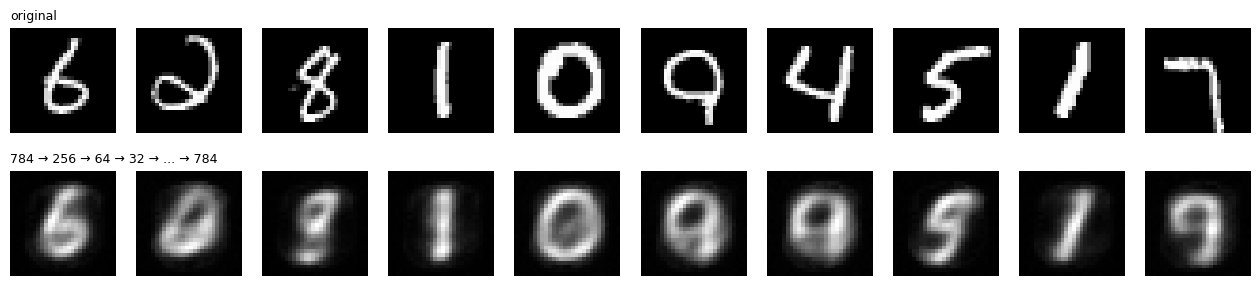

In [ ]:
SAE_model = StackedAutoEncoderClassifier(encoders_list, num_classes=10).to(device)
print(SAE_model)

test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    x = test_images[:10].view(10, -1).to(device)
    rec = SAE_model.reconstruir(x).view(10, 28, 28).cpu()
fig, axes = plt.subplots(2, 10, figsize=(16, 3.4))
for k in range(10):
    axes[0, k].imshow(test_images[k, 0], cmap="gray"); axes[0, k].axis("off")
    axes[1, k].imshow(rec[k], cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=9); axes[1, 0].set_title("784 → 256 → 64 → 32 → ... → 784", loc="left", fontsize=9)
plt.show()

### Fase 3: clasificador y fine-tuning, y la comparación que importa

Para saber si el preentrenamiento sirvió de algo hay que comparar contra la misma arquitectura **inicializada al azar** y entrenada con las mismas 1 000 imágenes etiquetadas. Corremos tres variantes:

- **A. Preentrenado, solo cabeza**: encoders congelados, se entrena la capa de clasificación (*feature extraction*).
- **B. Preentrenado + fine-tuning**: después de A, se descongela todo y se entrena con una tasa de aprendizaje menor.
- **C. Desde cero**: misma red, pesos al azar, se entrena todo desde el inicio.

In [ ]:
historias = {}

# A. Preentrenado, solo la cabeza
print("A. Preentrenado, solo cabeza")
historias["A. preentrenado, solo cabeza"] = train_classifier(SAE_model, labeled_loader, test_loader, epochs=num_classifier_epochs, lr=1e-3, trainable="head")

# B. Fine-tuning de toda la red (continúa desde A, tasa de aprendizaje menor)
print("B. Preentrenado + fine-tuning")
historias["B. preentrenado + fine-tuning"] = train_classifier(SAE_model, labeled_loader, test_loader, epochs=num_finetuning_epochs, lr=3e-4, trainable="all")

# C. Desde cero: misma arquitectura, pesos al azar
print("C. Desde cero")
torch.manual_seed(SEED)
scratch_model = StackedAutoEncoderClassifier([AutoEncoderLayer(dims[i], dims[i + 1]) for i in range(len(dims) - 1)], num_classes=10)
historias["C. desde cero"] = train_classifier(scratch_model, labeled_loader, test_loader, epochs=num_classifier_epochs + num_finetuning_epochs, lr=1e-3, trainable="all")

A. Preentrenado, solo cabeza
  [head] época  1/20  L(θ) = 2.3269  acc test = 0.1070
  [head] época  5/20  L(θ) = 2.2024  acc test = 0.2210
  [head] época 10/20  L(θ) = 2.0679  acc test = 0.4180
  [head] época 15/20  L(θ) = 1.9446  acc test = 0.5450
  [head] época 20/20  L(θ) = 1.8326  acc test = 0.6060
B. Preentrenado + fine-tuning
  [all] época  1/20  L(θ) = 1.8080  acc test = 0.6400
  [all] época  5/20  L(θ) = 1.7044  acc test = 0.6760
  [all] época 10/20  L(θ) = 1.5914  acc test = 0.6960
  [all] época 15/20  L(θ) = 1.4867  acc test = 0.7120
  [all] época 20/20  L(θ) = 1.3896  acc test = 0.7200
C. Desde cero
  [all] época  1/40  L(θ) = 2.3134  acc test = 0.1100
  [all] época  5/40  L(θ) = 2.2549  acc test = 0.1630
  [all] época 10/40  L(θ) = 2.0168  acc test = 0.3070
  [all] época 15/40  L(θ) = 1.7304  acc test = 0.3990
  [all] época 20/40  L(θ) = 1.4837  acc test = 0.4840
  [all] época 25/40  L(θ) = 1.2776  acc test = 0.6280
  [all] época 30/40  L(θ) = 1.0954  acc test = 0.6660
  [a

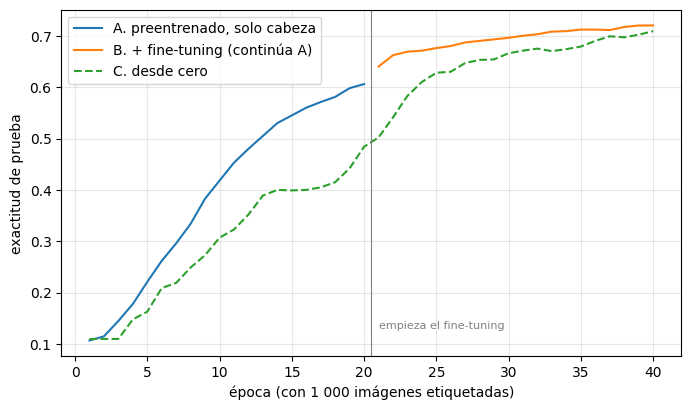

A. preentrenado, solo cabeza     acc test final = 0.6060
B. preentrenado + fine-tuning    acc test final = 0.7200
C. desde cero                    acc test final = 0.7090


In [ ]:
plt.figure(figsize=(8, 4.5))
accA, accB, accC = historias["A. preentrenado, solo cabeza"]["acc_test"], historias["B. preentrenado + fine-tuning"]["acc_test"], historias["C. desde cero"]["acc_test"]
plt.plot(range(1, len(accA) + 1), accA, label="A. preentrenado, solo cabeza")
plt.plot(range(len(accA) + 1, len(accA) + len(accB) + 1), accB, label="B. + fine-tuning (continúa A)")
plt.plot(range(1, len(accC) + 1), accC, label="C. desde cero", ls="--")
plt.axvline(len(accA) + 0.5, color="gray", lw=0.8); plt.text(len(accA) + 1, min(accC) + 0.02, "empieza el fine-tuning", color="gray", fontsize=8)
plt.xlabel("época (con 1 000 imágenes etiquetadas)"); plt.ylabel("exactitud de prueba"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
for nombre, h in historias.items():
    print(f"{nombre:32s} acc test final = {h['acc_test'][-1]:.4f}")

**Qué observar:**

1. Con solo la cabeza (A) la red ya clasifica bastante bien: la representación de 32 dimensiones aprendida *sin etiquetas* es útil para la tarea supervisada.
2. El fine-tuning (B) mejora sobre A: la representación se adapta a la tarea.
3. La red desde cero (C) converge más lento y, con pocas etiquetas, suele quedar por debajo de B. Con 60 000 etiquetas la diferencia tiende a desaparecer: el preentrenamiento vale más cuanto menos etiquetas hay. Prueben cambiando `num_train_samples` del `labeled_loader` a 300 y a 6000.
4. Vean la discusión de la sección 7 sobre por qué hoy nadie preentrena así... y por qué, a la vez, todo el mundo preentrena así.

In [ ]:
os.makedirs("models", exist_ok=True)
torch.save(SAE_model.state_dict(), "models/sae_model.pt")      # guardar el state_dict es la forma recomendada
print("guardado en models/sae_model.pt")

guardado en models/sae_model.pt


# 3. El mismo experimento en Keras, paso a paso

Repetimos el stacked autoencoder en Keras porque su API hace **explícitas** dos cosas que en PyTorch quedan escondidas en el código:

- Las capas son objetos que se pueden **reutilizar en varios modelos**: la misma `Dense` vive en el autoencoder de la capa 1 y en el clasificador final, y comparte sus pesos.
- El atributo `trainable` de una capa o de un modelo congela sus pesos, y `summary()` muestra cuántos parámetros son entrenables en cada fase.

Ojo con la trampa clásica de Keras: después de cambiar `trainable` **hay que volver a compilar**; si no, el cambio no tiene efecto.

Usamos los mismos subconjuntos de MNIST de la sección 2, convertidos a `numpy`.

In [ ]:
import keras
from keras import layers
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

def a_numpy(loader):
    xs, ys = [], []
    for images, labels in loader:
        xs.append(images.view(images.size(0), -1).numpy()); ys.append(labels.numpy())
    return np.concatenate(xs), np.concatenate(ys)

X_pre, _      = a_numpy(pretrain_loader)      # 6000 imágenes sin etiquetas (no usamos y)
X_lab, y_lab  = a_numpy(labeled_loader)       # 1000 imágenes con etiquetas
X_tst, y_tst  = a_numpy(test_loader)
print("preentrenamiento:", X_pre.shape, "| etiquetadas:", X_lab.shape, "| prueba:", X_tst.shape)

Keras 3.13.2 | backend: tensorflow
preentrenamiento: (6000, 784) | etiquetadas: (1000, 784) | prueba: (1000, 784)


## 3.1 Preentrenamiento capa por capa

Cada autoencoder es un `Sequential` de dos `Dense`. Guardamos los encoders en una lista y, para la capa siguiente, calculamos los códigos con `encoder.predict`.

In [ ]:
keras.utils.set_random_seed(SEED)
dims = [784, 256, 64, 32]
encoders_keras = []
entrada = X_pre

for i in range(len(dims) - 1):
    enc = layers.Dense(dims[i + 1], activation="sigmoid", name=f"enc_{i + 1}")
    dec = layers.Dense(dims[i],     activation="sigmoid", name=f"dec_{i + 1}")
    ae = keras.Sequential([keras.Input(shape=(dims[i],)), enc, dec], name=f"autoencoder_{i + 1}")
    ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    print(f"--- autoencoder {i + 1}: {dims[i]} → {dims[i + 1]} → {dims[i]}")
    ae.fit(entrada, entrada, epochs=num_layer_wise_epochs, batch_size=batch_size, verbose=0)
    print(f"    MSE final: {ae.evaluate(entrada, entrada, verbose=0):.5f}")
    encoders_keras.append(enc)
    # códigos para la capa siguiente (el encoder ya entrenado)
    entrada = keras.Sequential([keras.Input(shape=(dims[i],)), enc]).predict(entrada, verbose=0)

--- autoencoder 1: 784 → 256 → 784
    MSE final: 0.02363
--- autoencoder 2: 256 → 64 → 256
    MSE final: 0.02056
--- autoencoder 3: 64 → 32 → 64
    MSE final: 0.04533


## 3.2 Apilar los encoders y agregar la cabeza

El modelo `encoder_apilado` reutiliza las **mismas** capas `enc_1`, `enc_2`, `enc_3` (los mismos objetos, con los pesos ya entrenados). Lo congelamos entero con `trainable = False` y miren el `summary()`: solo la capa `softmax` tiene parámetros entrenables.

In [ ]:
encoder_apilado = keras.Sequential([keras.Input(shape=(784,))] + encoders_keras, name="encoder_apilado")
encoder_apilado.trainable = False                                   # fase A: feature extraction

clasificador = keras.Sequential([keras.Input(shape=(784,)), encoder_apilado, layers.Dense(10, activation="softmax", name="softmax")], name="sae_clasificador")
clasificador.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
clasificador.summary()

Model: "sae_clasificador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_apilado (Sequential)    │ (None, 32)             │       219,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,818 (858.66 KB)

 Trainable params: 330 (1.29 KB)

 Non-trainable params: 219,488 (857.38 KB)

In [ ]:
hist_A = clasificador.fit(X_lab, y_lab, epochs=num_classifier_epochs, batch_size=batch_size, validation_data=(X_tst, y_tst), verbose=0)
print(f"A. solo cabeza:  acc test = {hist_A.history['val_accuracy'][-1]:.4f}")

A. solo cabeza:  acc test = 0.3710


## 3.3 Fine-tuning: descongelar y **volver a compilar**

Cambiamos `trainable` a `True`, recompilamos con una tasa de aprendizaje menor y seguimos entrenando. Vean cómo cambian los parámetros entrenables en el `summary()`.

In [ ]:
encoder_apilado.trainable = True                                    # fase B: fine-tuning
clasificador.compile(optimizer=keras.optimizers.Adam(3e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])   # ¡recompilar!
clasificador.summary()
hist_B = clasificador.fit(X_lab, y_lab, epochs=num_finetuning_epochs, batch_size=batch_size, validation_data=(X_tst, y_tst), verbose=0)
print(f"B. + fine-tuning: acc test = {hist_B.history['val_accuracy'][-1]:.4f}")

Model: "sae_clasificador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_apilado (Sequential)    │ (None, 32)             │       219,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,818 (858.66 KB)

 Trainable params: 219,818 (858.66 KB)

 Non-trainable params: 0 (0.00 B)

B. + fine-tuning: acc test = 0.7290


## 3.4 La misma red desde cero

C. desde cero:    acc test = 0.8690


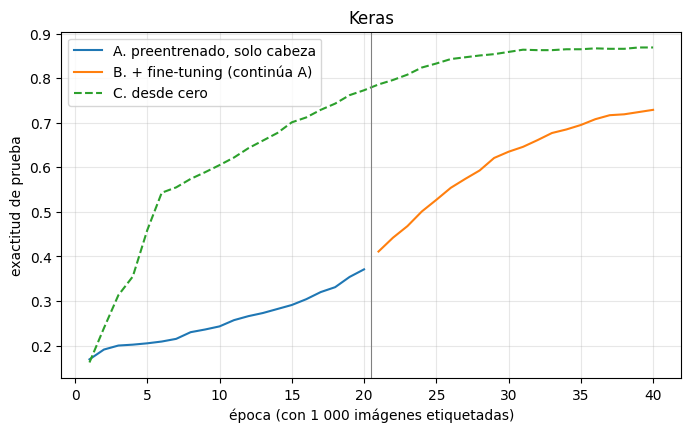

In [ ]:
keras.utils.set_random_seed(SEED)
desde_cero = keras.Sequential([keras.Input(shape=(784,))] + [layers.Dense(d, activation="sigmoid") for d in dims[1:]] + [layers.Dense(10, activation="softmax")], name="desde_cero")
desde_cero.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_C = desde_cero.fit(X_lab, y_lab, epochs=num_classifier_epochs + num_finetuning_epochs, batch_size=batch_size, validation_data=(X_tst, y_tst), verbose=0)
print(f"C. desde cero:    acc test = {hist_C.history['val_accuracy'][-1]:.4f}")

plt.figure(figsize=(8, 4.5))
nA, nB = len(hist_A.history["val_accuracy"]), len(hist_B.history["val_accuracy"])
plt.plot(range(1, nA + 1), hist_A.history["val_accuracy"], label="A. preentrenado, solo cabeza")
plt.plot(range(nA + 1, nA + nB + 1), hist_B.history["val_accuracy"], label="B. + fine-tuning (continúa A)")
plt.plot(range(1, nA + nB + 1), hist_C.history["val_accuracy"], ls="--", label="C. desde cero")
plt.axvline(nA + 0.5, color="gray", lw=0.8)
plt.xlabel("época (con 1 000 imágenes etiquetadas)"); plt.ylabel("exactitud de prueba"); plt.title("Keras"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Qué observar:** el resultado cualitativo es el mismo que en PyTorch (A < B, y C por debajo o convergiendo más lento). Las diferencias numéricas vienen de inicializaciones distintas; lo que no cambia es la idea. Y noten el detalle de ingeniería: en Keras, el *qué se entrena* se declara con `trainable` y se hace efectivo con `compile`; en PyTorch, con `requires_grad` y con qué parámetros recibe el optimizador.

# 4. Redes residuales (ResNet): la otra forma de entrenar redes profundas

El stacked autoencoder resolvía el problema de entrenar redes profundas **por la inicialización**: preentrenar capa por capa para no arrancar desde el azar. Diez años después, He et al. (2016) lo resolvieron **por la arquitectura**, y esa es la solución que se usa hoy.

## El problema: la degradación

Uno esperaría que una red más profunda fuera al menos tan buena como una menos profunda: las capas extra podrían aprender la identidad y listo. En la práctica no pasaba. En el paper de ResNet, una red *plain* de 56 capas tiene **más error de entrenamiento** que una de 20 sobre CIFAR-10 (su Fig. 1). No es sobreajuste, es optimización: al descenso del gradiente le cuesta muchísimo encontrar la identidad en una pila de capas no lineales, y además los gradientes se desvanecen al atravesarlas (recuerden la clase de inicialización).

## La idea: que la capa aprenda el residuo

En lugar de pedirle a un bloque de capas que aprenda una función $H(\mathbf{x})$, se le pide que aprenda la **diferencia** respecto a la entrada:

$$
\mathbf{y} = F(\mathbf{x}) + \mathbf{x}, \qquad F(\mathbf{x}) = H(\mathbf{x}) - \mathbf{x}
$$

donde $F$ son dos o tres capas (convolución, *batch norm*, ReLU) y el término $+\,\mathbf{x}$ es la **conexión de atajo** (*skip connection* o *shortcut*). Tres consecuencias:

1. **La identidad es gratis.** Si el bloque no sirve, basta con que $F \to 0$ (pesos cercanos a cero): la red profunda nunca es peor que la menos profunda.
2. **El gradiente tiene un camino directo.** Para un bloque, $\partial \mathbf{y} / \partial \mathbf{x} = \mathbf{I} + \partial F / \partial \mathbf{x}$: aunque $\partial F / \partial \mathbf{x}$ sea minúsculo, el gradiente pasa por la identidad y llega a las primeras capas. Es la misma suma que vimos en el baseline de la Tarea 2: `layers.add([x, residual])`.
3. **Cuando las formas no coinciden** (otro número de canales, otra resolución), el atajo lleva una proyección: una convolución $1 \times 1$, con *stride* si hace falta, $\mathbf{y} = F(\mathbf{x}) + \mathbf{W}_s \mathbf{x}$. Exactamente la proyección que les pedimos explicar en el examen.

## Las ResNet reales

- **Bloque básico** (ResNet-18 y 34): dos convoluciones $3 \times 3$, cada una seguida de `BatchNorm`; ReLU después de la suma.
- **Bloque cuello de botella** (ResNet-50, 101, 152): $1 \times 1$ para reducir canales, $3 \times 3$, $1 \times 1$ para volver a expandir. Mismo campo receptivo, muchos menos parámetros.
- 18, 34, 50, 101, 152: el número de capas con pesos. ResNet-152 ganó ImageNet 2015 con 3,57 % de error top-5, y la receta (bloques residuales + batch norm) está debajo de casi todo lo que vino después, Transformers incluidos.

La celda siguiente dibuja el bloque básico y el de cuello de botella (nuestro propio esquema; las figuras originales son la Fig. 2 y la Fig. 5 de He et al., 2016).

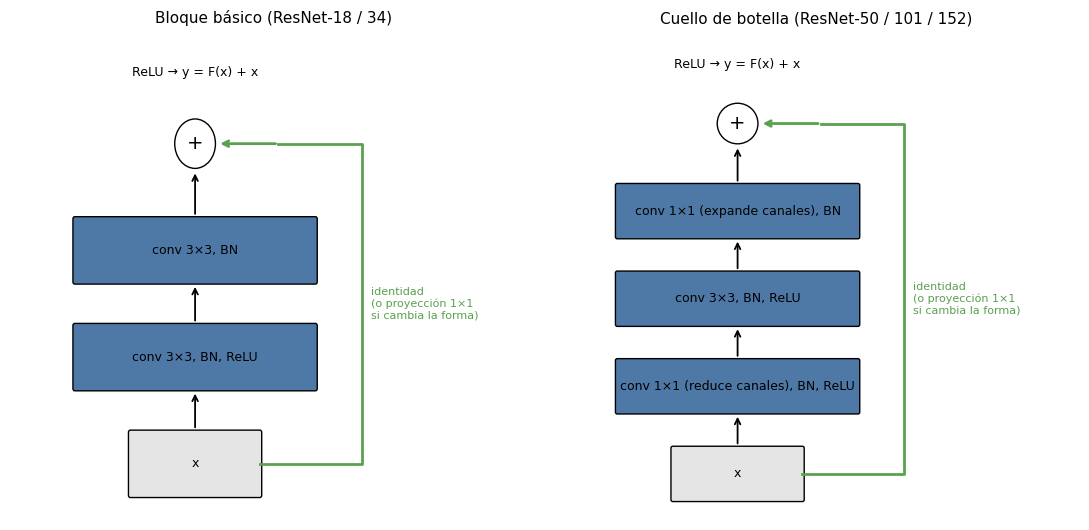

In [ ]:
def dibujar_bloques_residuales():
    import matplotlib.patches as mpatches
    azul, verde, gris = "#4e79a7", "#59a14f", "#e5e5e5"
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))

    def caja(ax, y, texto, color=azul, w=2.6):
        ax.add_patch(mpatches.FancyBboxPatch((2.5 - w / 2, y - 0.28), w, 0.56, boxstyle="round,pad=0.02", fc=color, ec="black"))
        ax.text(2.5, y, texto, ha="center", va="center", fontsize=9)

    def columna(ax, titulo, capas):
        ax.set_title(titulo, fontsize=11)
        ys = [0.7 + 0.95 * k for k in range(len(capas) + 2)]
        caja(ax, ys[0], "x", gris, w=1.4)
        for k, texto in enumerate(capas):
            caja(ax, ys[k + 1], texto)
            ax.annotate("", xy=(2.5, ys[k + 1] - 0.3), xytext=(2.5, ys[k] + 0.3), arrowprops=dict(arrowstyle="->", lw=1.3))
        ax.add_patch(mpatches.Circle((2.5, ys[-1]), 0.22, fc="white", ec="black")); ax.text(2.5, ys[-1], "+", ha="center", va="center", fontsize=14)
        ax.annotate("", xy=(2.5, ys[-1] - 0.24), xytext=(2.5, ys[-2] + 0.3), arrowprops=dict(arrowstyle="->", lw=1.3))
        # atajo (identidad)
        ax.plot([2.5 + 0.7, 4.3, 4.3, 2.5 + 0.9], [ys[0], ys[0], ys[-1], ys[-1]], color=verde, lw=2)
        ax.annotate("", xy=(2.5 + 0.24, ys[-1]), xytext=(2.5 + 0.9, ys[-1]), arrowprops=dict(arrowstyle="->", color=verde, lw=2))
        ax.text(4.4, (ys[0] + ys[-1]) / 2, "identidad\n(o proyección 1×1\nsi cambia la forma)", color=verde, fontsize=8, va="center")
        ax.text(2.5, ys[-1] + 0.6, "ReLU → y = F(x) + x", ha="center", fontsize=9)
        ax.set_xlim(0.5, 6.2); ax.set_ylim(0.2, ys[-1] + 1.0); ax.axis("off")

    columna(axes[0], "Bloque básico (ResNet-18 / 34)", ["conv 3×3, BN, ReLU", "conv 3×3, BN"])
    columna(axes[1], "Cuello de botella (ResNet-50 / 101 / 152)", ["conv 1×1 (reduce canales), BN, ReLU", "conv 3×3, BN, ReLU", "conv 1×1 (expande canales), BN"])
    plt.tight_layout(); plt.show()

dibujar_bloques_residuales()

## El experimento: red *plain* contra red residual

Para verlo sin esperar horas de CIFAR-10, lo hacemos con redes completamente conectadas sobre MNIST, igual que en la sección 2: una pila de 30 capas de 128 unidades con ReLU. La versión *plain* las encadena; la residual suma la entrada de cada bloque a su salida. Misma profundidad, mismos parámetros, misma inicialización por defecto de PyTorch, mismo optimizador.

Fíjense primero en el gradiente **antes de entrenar**: la norma de $\partial L / \partial \mathbf{W}_k$ capa por capa.

parámetros plain: 597130 | residual: 597130


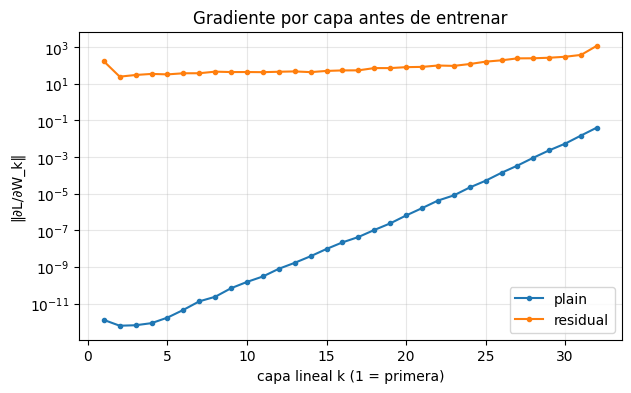

In [ ]:
class BloqueResidualMLP(nn.Module):
    '''y = x + ReLU(W x + b): un bloque residual de una capa, para la demostración.'''
    def __init__(self, d):
        super().__init__()
        self.lineal = nn.Linear(d, d)

    def forward(self, x):
        return x + F.relu(self.lineal(x))


def red_profunda(profundidad=30, ancho=128, residual=False, n_clases=10):
    capas = [nn.Linear(784, ancho), nn.ReLU()]
    for _ in range(profundidad):
        capas.append(BloqueResidualMLP(ancho) if residual else nn.Sequential(nn.Linear(ancho, ancho), nn.ReLU()))
    capas.append(nn.Linear(ancho, n_clases))
    return nn.Sequential(*capas)


def normas_gradiente(model, loader):
    '''Norma del gradiente de los pesos de cada capa lineal tras un pase hacia atrás sobre un batch.'''
    model.to(device).train(); model.zero_grad()
    images, labels = next(iter(loader))
    loss = nn.CrossEntropyLoss()(model(images.view(images.size(0), -1).to(device)), labels.to(device))
    loss.backward()
    return [m.weight.grad.norm().item() for m in model.modules() if isinstance(m, nn.Linear)]


torch.manual_seed(SEED); plain = red_profunda(residual=False)
torch.manual_seed(SEED); resid = red_profunda(residual=True)
print("parámetros plain:", sum(p.numel() for p in plain.parameters()), "| residual:", sum(p.numel() for p in resid.parameters()))

plt.figure(figsize=(7, 4))
for nombre, m in [("plain", plain), ("residual", resid)]:
    g = normas_gradiente(m, pretrain_loader)
    plt.semilogy(range(1, len(g) + 1), g, marker=".", label=nombre)
plt.xlabel("capa lineal k (1 = primera)"); plt.ylabel("‖∂L/∂W_k‖"); plt.title("Gradiente por capa antes de entrenar"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

En la red *plain* el gradiente de las primeras capas es órdenes de magnitud menor que el de las últimas: la señal de error se desvanece al atravesar 30 capas (y con la inicialización por defecto de PyTorch, que no es He, la varianza se reduce en cada una). En la residual, el atajo mantiene el gradiente en el mismo orden de magnitud a lo largo de toda la red. Ahora entrenamos las dos con las 6 000 imágenes etiquetadas.

  [plain, 30 capas] época 1/5  L(θ) = 2.3022  acc test = 0.1100
  [plain, 30 capas] época 2/5  L(θ) = 2.3012  acc test = 0.1100
  [plain, 30 capas] época 3/5  L(θ) = 2.3011  acc test = 0.1100
  [plain, 30 capas] época 4/5  L(θ) = 2.3011  acc test = 0.1100
  [plain, 30 capas] época 5/5  L(θ) = 2.3008  acc test = 0.1100
  [residual, 30 capas] época 1/5  L(θ) = 5.0172  acc test = 0.1380
  [residual, 30 capas] época 2/5  L(θ) = 1.7581  acc test = 0.5840
  [residual, 30 capas] época 3/5  L(θ) = 0.9467  acc test = 0.7670
  [residual, 30 capas] época 4/5  L(θ) = 0.6753  acc test = 0.7980
  [residual, 30 capas] época 5/5  L(θ) = 0.5011  acc test = 0.8450


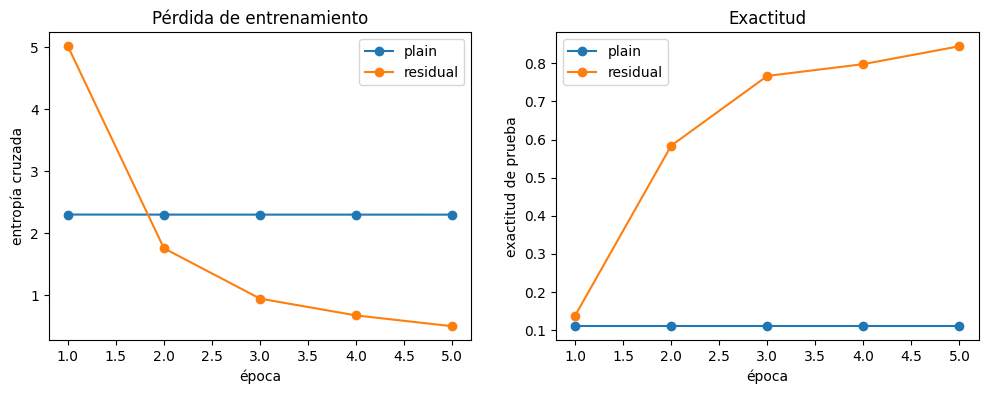

In [ ]:
def entrenar_clasificador_mlp(model, loader, test_loader, epochs=5, lr=1e-3, etiqueta=""):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr); criterion = nn.CrossEntropyLoss()
    hist = {"loss": [], "acc_test": []}
    for epoch in range(epochs):
        model.train(); total, n = 0.0, 0
        for images, labels in loader:
            x, y = images.view(images.size(0), -1).to(device), labels.to(device)
            optimizer.zero_grad(); loss = criterion(model(x), y); loss.backward(); optimizer.step()
            total += loss.item() * x.size(0); n += x.size(0)
        hist["loss"].append(total / n); hist["acc_test"].append(accuracy(model, test_loader))
        print(f"  [{etiqueta}] época {epoch + 1}/{epochs}  L(θ) = {hist['loss'][-1]:.4f}  acc test = {hist['acc_test'][-1]:.4f}")
    return hist

hist_plain = entrenar_clasificador_mlp(plain, pretrain_loader, test_loader, epochs=5, etiqueta="plain, 30 capas")
hist_resid = entrenar_clasificador_mlp(resid, pretrain_loader, test_loader, epochs=5, etiqueta="residual, 30 capas")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nombre, h in [("plain", hist_plain), ("residual", hist_resid)]:
    ep = range(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], marker="o", label=nombre); ax[1].plot(ep, h["acc_test"], marker="o", label=nombre)
ax[0].set_xlabel("época"); ax[0].set_ylabel("entropía cruzada"); ax[0].set_title("Pérdida de entrenamiento"); ax[0].legend()
ax[1].set_xlabel("época"); ax[1].set_ylabel("exactitud de prueba"); ax[1].set_title("Exactitud"); ax[1].legend()
plt.show()

**Qué observarmos?**

1. La red *plain* de 30 capas se queda cerca de $\ln 10 \approx 2.30$ de pérdida (adivinar al azar) o aprende muy lento: no es que le falte capacidad, es que el gradiente no llega. La residual aprende desde la primera época.
2. Es la misma enfermedad que motivó el stacked autoencoder, con otra cura: allí se preentrenaba capa por capa para arrancar desde un buen punto (mejoramos la **inicialización**); aquí se cambia la arquitectura para que el gradiente siempre tenga un camino. La segunda cura es más simple y escala mejor, por eso ganó.
3. Ejercicio: inicialicen la red *plain* con He (`nn.init.kaiming_normal_`) y repitan. Mejora, pero a 30 capas sigue por debajo de la residual; a 100 capas la diferencia es abismal.

## La ResNet de verdad: el bloque de torchvision

Antes de hacerle fine-tuning a una ResNet18 en la sección siguiente, miren cómo está hecha. `layer1[0]` es un `BasicBlock`: dos `conv 3×3` con `BatchNorm`, y su `forward` suma `identity` antes de la última ReLU. En `layer2[0]` el bloque pasa de 64 a 128 canales y reduce la resolución, así que el atajo lleva `downsample`: la convolución $1 \times 1$ con stride 2 del esquema.

In [ ]:
import inspect, copy
from torchvision.models import resnet18
from torchvision.models.resnet import BasicBlock

rn = resnet18(weights=None)

### Verificamos la capa 0

In [ ]:
print(rn.layer1[0])

BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


Verifiquemos ahora el paso hacia adelante de BasicBlock

In [ ]:
print(inspect.getsource(BasicBlock.forward))


    def forward(self, x: Tensor) -> Tensor:
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out



En cambio, layer2[0].downsample existe y cambia de forma → atajo con proyección 1×1, stride 2

In [ ]:

print(rn.layer2[0].downsample)

layer2[0].downsample (cambia de forma → atajo con proyección 1×1, stride 2):
Sequential(
  (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
  (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


In [ ]:
rn.layer2[0]

BasicBlock(
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (downsample): Sequential(
    (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
)

### Verifiquemos la identidad

Si la rama $F(x)$ se apagara, fíjense cómo el bloque retorna la entrada:

In [ ]:
# Comprobación: si la rama F(x) se apaga, el bloque devuelve su entrada tal cual
bloque = copy.deepcopy(rn.layer1[0]).eval()
with torch.no_grad():
    bloque.bn2.weight.zero_()                 # la última BN multiplica por 0 → F(x) = 0
    x = torch.rand(1, 64, 8, 8)               # entrada no negativa, como la salida de una ReLU
    y = bloque(x)                             # y = ReLU(F(x) + x) = ReLU(x) = x


Es el $bloque(x) == x$ con $F(x) = 0$?

In [ ]:
torch.allclose(y, x)

True

### Verificando información dentro de la red

#### Parámetros

In [ ]:
print("\ncapas con pesos:", sum(1 for m in rn.modules() if isinstance(m, (nn.Conv2d, nn.Linear))),
      "| parámetros:", sum(p.numel() for p in rn.parameters()))


capas con pesos: 21 | parámetros: 11689512


#### Graficando la red

In [ ]:
!pip -q install torchview torchinfo

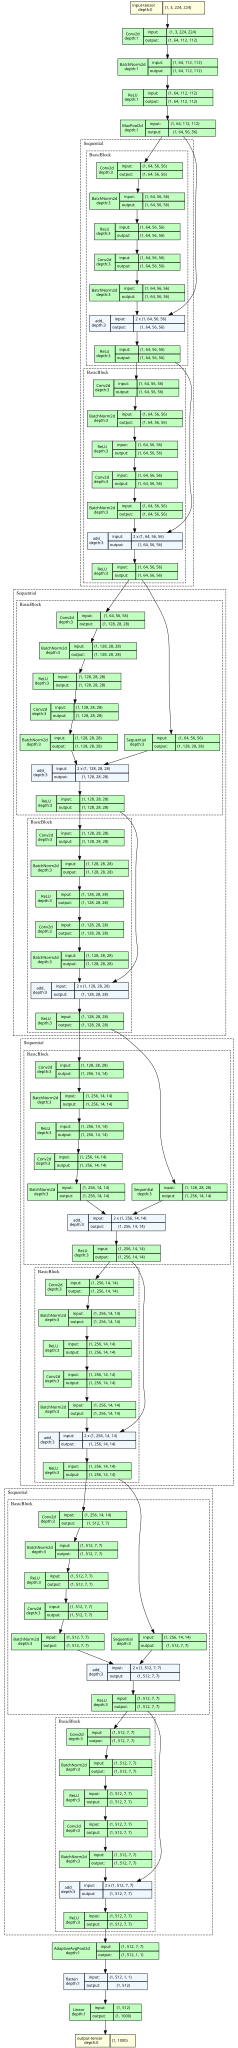

In [ ]:
from torchview import draw_graph

# Toda la ResNet18. depth=3 baja hasta el interior de cada BasicBlock, que es donde está la suma del atajo
grafo = draw_graph(
    rn,
    input_size=(1, 3, 224, 224),
    depth=3,
    expand_nested=True,
    hide_inner_tensors=True,
    graph_dir="TB",
    roll=False
)
# Se dibuja inline
# Para guardarlo: grafo.visual_graph.render("resnet18", format="png")
grafo.visual_graph

Podemos visualizar una capa en específico

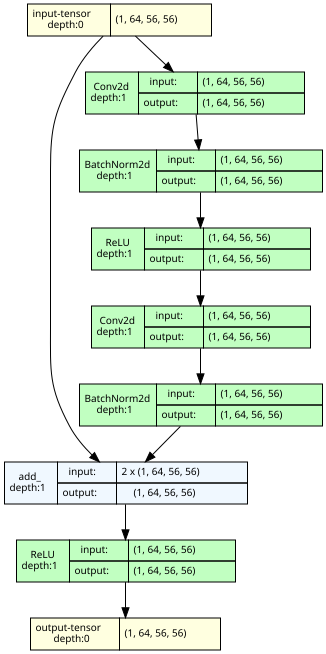

In [ ]:
# Zoom en el bloque que cambia de forma: aquí se ven las dos ramas que llegan al "add"
grafo_bloque = draw_graph(
    rn.layer1[0],
    input_size=(1, 64, 56, 56),
    depth=3, expand_nested=True, hide_inner_tensors=True, graph_dir="TB"
)
grafo_bloque.visual_graph

In [ ]:
from torchinfo import summary
summary(rn, input_size=(1, 3, 224, 224), depth=3,
        col_names=("input_size", "output_size", "num_params", "kernel_size"), row_settings=("var_names",))

Layer (type (var_name))                  Input Shape               Output Shape              Param #                   Kernel Shape
ResNet (ResNet)                          [1, 3, 224, 224]          [1, 1000]                 --                        --
├─Conv2d (conv1)                         [1, 3, 224, 224]          [1, 64, 112, 112]         9,408                     [7, 7]
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]         [1, 64, 112, 112]         128                       --
├─ReLU (relu)                            [1, 64, 112, 112]         [1, 64, 112, 112]         --                        --
├─MaxPool2d (maxpool)                    [1, 64, 112, 112]         [1, 64, 56, 56]           --                        3
├─Sequential (layer1)                    [1, 64, 56, 56]           [1, 64, 56, 56]           --                        --
│    └─BasicBlock (0)                    [1, 64, 56, 56]           [1, 64, 56, 56]           --                        --
│    │    └

# 5. Fine-Tuning

**Fine-tuning** (ajuste fino) es una técnica de aprendizaje profundo que consiste en **ajustar una red neuronal previamente entrenada** (por ejemplo, en una tarea o dataset grande) para mejorar su rendimiento en una **nueva tarea o dataset relacionado**.

En lugar de entrenar un modelo desde cero, se aprovechan los **pesos preentrenados** como una buena inicialización y se continúa el entrenamiento sobre un nuevo conjunto de datos, generalmente más pequeño. Es exactamente lo que hicimos en la fase 3 de la sección 2, con una diferencia de escala: allí preentrenamos nosotros con 6 000 imágenes; aquí alguien preentrenó con millones.

## Motivación

- Reducir el tiempo de entrenamiento
- Evitar el sobreajuste en datasets pequeños
- Transferir conocimiento aprendido en una tarea a otra relacionada

## Formalización

Supón que tienes un modelo entrenado con parámetros $\theta_0$, aprendido sobre un conjunto de datos grande $D_{\mathrm{pretrain}}$:

$$
\theta_0 = \arg\min_{\theta} L_{\mathrm{pretrain}}(D_{\mathrm{pretrain}}, \theta)
$$

Luego, en lugar de entrenar desde cero, inicias con $\theta_0$ y haces un nuevo entrenamiento sobre un conjunto más específico $D_{\mathrm{target}}$:

$$
\theta^* = \arg\min_{\theta} L_{\mathrm{target}}(D_{\mathrm{target}}, \theta)
$$

donde:

- $L_{\mathrm{target}}$ puede ser distinta a $L_{\mathrm{pretrain}}$ (en el stacked autoencoder: MSE para preentrenar, entropía cruzada para la tarea)
- En muchos casos, solo una parte de los parámetros se ajusta, mientras otros se congelan

## Estrategias de Fine-Tuning

1. **Congelar capas base y entrenar solo las finales** (*feature extraction*):
   - Ideal cuando el nuevo dataset es pequeño
   - Solo se actualizan algunos parámetros $\theta_{\mathrm{fine}} \subset \theta$

2. **Entrenar toda la red con tasa de aprendizaje baja**:
   - Útil si el nuevo dataset es grande o similar al original
   - Se evita destruir el conocimiento previamente aprendido

3. **Descongelar gradualmente**:
   - Se entrena primero solo la cabeza (*top layers*), luego se descongelan capas intermedias, de la última hacia la primera

## Ejemplo típico de uso

- Usar un modelo como `ResNet` o `BERT` preentrenado
- Reemplazar la capa de salida final
- Entrenar solo esa capa por unas pocas épocas
- Luego ajustar toda la red (o sus últimas capas) con una tasa de aprendizaje pequeña

## Ventajas

- Rápida convergencia
- Buen rendimiento incluso con pocos datos
- Aprovecha representaciones generales aprendidas

## Riesgos

- **Catastrophic forgetting** si se entrena agresivamente sobre un nuevo dominio muy distinto: se destruye lo aprendido
- Si el dataset nuevo es muy diferente al del preentrenamiento, el fine-tuning puede ser inefectivo sin más adaptación

In [ ]:
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

### Viendo el modelo ResNet

ResNet18 preentrenada en ImageNet (1,2 millones de imágenes, 1 000 clases): la misma arquitectura que acabamos de ver, ahora con pesos aprendidos. Fíjense en la última capa, `fc`: es la que vamos a reemplazar.

In [ ]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### Fine-tuning sobre MNIST

Tres detalles prácticos:

- ResNet espera imágenes RGB de $224 \times 224$ normalizadas con la media y desviación de ImageNet: usamos `weights.transforms()`, que ya lo hace, y convertimos el gris a tres canales.
- MNIST completo a $224 \times 224$ tarda mucho: usamos 5 000 imágenes de entrenamiento y 1 000 de prueba.
- Comparamos la estrategia 1 (solo `fc`) con la 3 (descongelar además el último bloque, `layer4`, con tasa de aprendizaje menor).

In [ ]:
import time, functools

TIEMPOS = {}

def cronometro(func):
    '''Mide cuánto tarda cada llamada a `func`, lo imprime y lo guarda en TIEMPOS.'''
    @functools.wraps(func)
    def envoltura(*args, **kwargs):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        resultado = func(*args, **kwargs)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        segundos = time.perf_counter() - t0
        nombre = kwargs.get("etiqueta", func.__name__)
        TIEMPOS[nombre] = segundos
        print(f"Tiempo: {nombre}: {segundos:.1f} s")
        return resultado
    return envoltura

@cronometro
def entrenar_epocas(model, loader, optimizer, epochs, etiqueta):
    criterion = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train(); running = 0.0
        for images, labels in tqdm(loader, desc=f"[{etiqueta}] época {epoch + 1}/{epochs}", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running += loss.item()
        print(f"[{etiqueta}] época {epoch + 1} - L(θ) = {running / len(loader):.4f}")


@torch.no_grad()
def accuracy_imgs(model, loader):
    model.eval(); correct = total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model(images).argmax(1) == labels).sum().item(); total += labels.size(0)
    return correct / total

In [ ]:
transform_resnet = transforms.Compose([transforms.Grayscale(num_output_channels=3), weights.transforms()])

g = torch.Generator().manual_seed(SEED)
mnist_train = datasets.MNIST(root="./data", train=True,  download=True, transform=transform_resnet)
mnist_test  = datasets.MNIST(root="./data", train=False, download=True, transform=transform_resnet)
train_loader_rn = DataLoader(Subset(mnist_train, torch.randperm(len(mnist_train), generator=g)[:5000].tolist()), batch_size=64, shuffle=True)
test_loader_rn  = DataLoader(Subset(mnist_test,  torch.randperm(len(mnist_test),  generator=g)[:1000].tolist()), batch_size=64, shuffle=False)



#### Estrategia 1: congelar todo, reemplazar y entrenar solo la cabeza

In [ ]:
model = resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

In [ ]:
# La capa nueva sí es entrenable
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

In [ ]:
print("parámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad), "de", sum(p.numel() for p in model.parameters()))

parámetros entrenables: 5130 de 11181642


In [ ]:
entrenar_epocas(model, train_loader_rn, optim.Adam(model.fc.parameters(), lr=1e-3), epochs=2, etiqueta="solo fc")
acc_fc = accuracy_imgs(model, test_loader_rn)
print(f"Accuracy (backbone congelado, solo fc): {100 * acc_fc:.2f}%")

[solo fc] época 1/2:   0%|          | 0/79 [00:00<?, ?it/s]

[solo fc] época 1 - L(θ) = 1.3416


[solo fc] época 2/2:   0%|          | 0/79 [00:00<?, ?it/s]

[solo fc] época 2 - L(θ) = 0.6490
Tiempo: solo fc: 35.3 s
Accuracy (backbone congelado, solo fc): 91.00%


#### Estrategia 2: toda la red entrenable desde el inicio, con tasa de aprendizaje baja

In [ ]:
torch.manual_seed(SEED)
model2 = resnet18(weights=weights)                       # parte de nuevo de los pesos de ImageNet
model2.fc = nn.Linear(model2.fc.in_features, 10)         # misma cabeza nueva que en la estrategia 1
model2 = model2.to(device)
print("parámetros entrenables:", sum(p.numel() for p in model2.parameters() if p.requires_grad),
      "de", sum(p.numel() for p in model2.parameters()))

entrenar_epocas(model2, train_loader_rn, optim.Adam(model2.parameters(), lr=1e-3), epochs=2, etiqueta="toda la red")
acc_todo = accuracy_imgs(model2, test_loader_rn)
print(f"Accuracy (toda la red, lr=1e-3): {100 * acc_todo:.2f}%")

parámetros entrenables: 11181642 de 11181642


[toda la red] época 1/2:   0%|          | 0/79 [00:00<?, ?it/s]

[toda la red] época 1 - L(θ) = 0.1920


[toda la red] época 2/2:   0%|          | 0/79 [00:00<?, ?it/s]

[toda la red] época 2 - L(θ) = 0.0626
Tiempo: toda la red: 57.8 s
Accuracy (toda la red, lr=1e-4): 97.50%


#### Estrategia 3: descongelar además el último bloque (layer4) y seguir con tasa de aprendizaje menor

In [ ]:
model3 = resnet18(weights=weights)

for param in model3.parameters():
    param.requires_grad = False

for param in model3.layer4.parameters():
    param.requires_grad = True

model3.fc = nn.Linear(model3.fc.in_features, 10)
model3 = model3.to(device)

params = [p for p in model3.parameters() if p.requires_grad]
print("parámetros entrenables:", sum(p.numel() for p in params))

entrenar_epocas(model3, train_loader_rn, optim.Adam(params, lr=1e-3), epochs=2, etiqueta="fc + layer4")
acc_l4 = accuracy_imgs(model3, test_loader_rn)
print(f"Accuracy (fc + layer4): {100 * acc_l4:.2f}%")

parámetros entrenables: 8398858


[fc + layer4] época 1/2:   0%|          | 0/79 [00:00<?, ?it/s]

[fc + layer4] época 1 - L(θ) = 0.1825


[fc + layer4] época 2/2:   0%|          | 0/79 [00:00<?, ?it/s]

[fc + layer4] época 2 - L(θ) = 0.0249
Tiempo: fc + layer4: 36.9 s
Accuracy (fc + layer4): 96.90%


In [ ]:
print(f"{'estrategia':38s} {'épocas':>6s} {'accuracy':>9s} {'tiempo':>8s}")
print(f"{'1. solo fc (backbone congelado)':38s} {2:6d} {100 * acc_fc:8.2f}% {TIEMPOS['solo fc']:7.1f}s")
print(f"{'2. toda la red, lr=1e-3':38s} {2:6d} {100 * acc_todo:8.2f}% {TIEMPOS['toda la red']:7.1f}s")
print(f"{'3. fc + layer4':38s} {2:6d} {100 * acc_l4:8.2f}% {TIEMPOS['fc + layer4']:7.1f}s")

estrategia                             épocas  accuracy   tiempo
1. solo fc (backbone congelado)             2    91.00%    35.3s
2. toda la red, lr=1e-3                     2    97.50%    57.8s
3. fc + layer4                              2    96.90%    36.9s


**Qué observar:** con el *backbone* congelado la red ya clasifica dígitos aunque ImageNet no tiene ninguno: los filtros de bordes, texturas y formas sirven para casi cualquier imagen. Descongelar `layer4` con tasa de aprendizaje baja adapta las características más específicas al nuevo dominio. Descongelar *todo* con tasa alta sería el camino al *catastrophic forgetting*.

# 6. Transfer Learning (Aprendizaje por Transferencia)

**Transfer learning** es una técnica de aprendizaje automático en la que un modelo entrenado previamente sobre una tarea **se reutiliza** parcial o totalmente para otra tarea **relacionada**. En lugar de entrenar un modelo desde cero, se **aprovecha el conocimiento aprendido** en una tarea base y se adapta al nuevo problema.

## Ejemplos

- Se entrena una red profunda (por ejemplo, ResNet, BERT, ViT) en un gran dataset genérico como **ImageNet** o **Wikipedia**.
- Luego, se reutiliza ese modelo como punto de partida para una tarea diferente:
  - Clasificación de dígitos manuscritos (MNIST)
  - Clasificación médica de imágenes de rayos X
  - Análisis de sentimientos en tweets

## Fundamento matemático

- $D_S$: conjunto de datos origen (*source*), con tarea $T_S$
- $D_T$: conjunto de datos destino (*target*), con tarea $T_T$

El objetivo es aprender un modelo $f_T$ para la tarea $T_T$ utilizando el conocimiento aprendido en $T_S$, donde $T_S \neq T_T$ pero **comparten representación o características comunes**.

## Estrategias comunes

| Estrategia | Qué se entrena | Cuándo |
|---|---|---|
| **Feature extraction** | solo la cabeza nueva; el *backbone* queda congelado | pocos datos, dominio parecido |
| **Fine-tuning** | todo el modelo o sus últimas capas, con tasa de aprendizaje baja | más datos, o dominio distinto |

## Ventajas

- **Rápida convergencia**: el modelo ya "sabe" detectar patrones útiles.
- **Mejor rendimiento con pocos datos**.
- **Reducción de costos computacionales**: nadie entrena un ViT desde cero para 1 000 fotos.

## Limitaciones

- Si la tarea destino es muy diferente, el conocimiento transferido puede **no ser útil** o dañar el rendimiento (**negative transfer**).
- Requiere cuidado al elegir qué capas congelar o afinar.

## Hugging Face

[Hugging Face](https://huggingface.co/models) es el repositorio de modelos preentrenados más grande que existe, y la librería `transformers` da una interfaz uniforme para cargarlos: un **procesador** que prepara la entrada como el modelo la espera, y un **modelo** con o sin cabeza para una tarea. Vamos a hacer dos cosas con un *Vision Transformer* (ViT): usarlo tal cual, y hacerle *fine-tuning* a un dataset pequeño.

In [ ]:
!pip install -q transformers datasets

## 6.1 Inferencia con un modelo preentrenado

Dos modelos de ImageNet (1 000 clases) con la misma interfaz: `microsoft/resnet-50`, la ResNet-50 que ya conocen, y `google/vit-base-patch16-224`, un *Vision Transformer* (más abajo explicamos qué es). Sin entrenar nada, los dos predicen la clase de una foto.

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

...

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

google/vit-base-patch16-224      → Egyptian cat


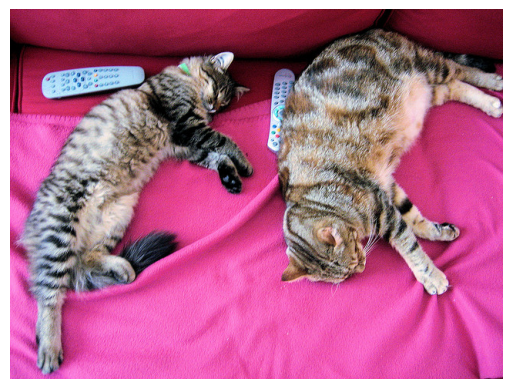

In [ ]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
from PIL import Image
import requests

url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw)

def predecir(checkpoint, image):
    processor = AutoImageProcessor.from_pretrained(checkpoint)
    model = AutoModelForImageClassification.from_pretrained(checkpoint).eval()
    with torch.no_grad():
        logits = model(**processor(images=image, return_tensors="pt")).logits
    return model.config.id2label[logits.argmax(-1).item()]

for checkpoint in ["microsoft/resnet-50", "google/vit-base-patch16-224"]:
    print(f"{checkpoint:32s} → {predecir(checkpoint, image)}")
plt.imshow(image); plt.axis("off"); plt.show()

## 6.2 Fine-tuning con Hugging Face: ResNet-50

**Dataset:** `beans`, 1 034 fotos de hojas de frijol en 3 clases (dos enfermedades y sano). Pequeño, nada que ver con ImageNet, y aun así una red preentrenada lo resuelve en minutos.

**Modelo:** `microsoft/resnet-50`, la ResNet-50 de la sección 4 preentrenada en ImageNet. Al cargarla con `AutoModelForImageClassification`, `num_labels=3` e `ignore_mismatched_sizes=True`, la librería descarta la cabeza de 1 000 clases y crea una nueva, al azar, con 3 salidas: exactamente lo que hicimos con `model.fc` en la sección 5.

El flujo es el mismo de toda la clase, y lo escribimos **una sola vez** en `ajustar`, para cualquier modelo de clasificación de imágenes del Hub:

1. El `processor` del modelo prepara las entradas como él las espera (tamaño, media y desviación del preentrenamiento).
2. Fase A: congelar el *backbone* (`model.base_model`, que en una ResNet es `model.resnet` y en un ViT `model.vit`) y entrenar solo la cabeza (`model.classifier`).
3. Fase B: descongelar todo y hacer fine-tuning con tasa de aprendizaje baja.

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
clases: ['angular_leaf_spot', 'bean_rust', 'healthy']


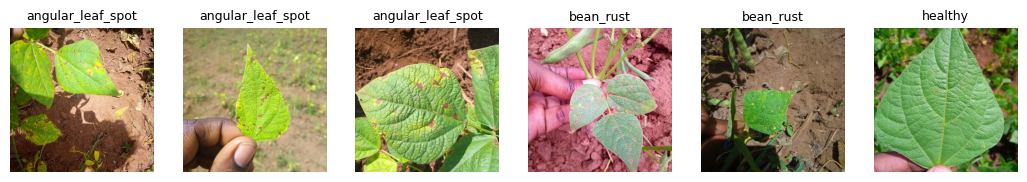

In [ ]:
from datasets import load_dataset

ds = load_dataset("AI-Lab-Makerere/beans")
print(ds)
etiquetas = ds["train"].features["labels"].names
print("clases:", etiquetas)

fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for k, ax in enumerate(axes):
    ej = ds["train"][k * 150]
    ax.imshow(ej["image"]); ax.set_title(etiquetas[ej["labels"]], fontsize=9); ax.axis("off")
plt.show()

In [ ]:
def preparar_loaders(checkpoint, batch_size=16):
    '''Loaders de beans con el processor del checkpoint (cada modelo normaliza a su manera).'''
    processor = AutoImageProcessor.from_pretrained(checkpoint)

    def transformar(batch):
        inputs = processor([img.convert("RGB") for img in batch["image"]], return_tensors="pt")
        inputs["labels"] = batch["labels"]
        return inputs

    def collate(batch):
        return {"pixel_values": torch.stack([x["pixel_values"] for x in batch]),
                "labels": torch.tensor([x["labels"] for x in batch])}

    ds_prep = ds.with_transform(transformar)                        # se aplica al vuelo, batch por batch
    return (DataLoader(ds_prep["train"],      batch_size=batch_size, shuffle=True,  collate_fn=collate),
            DataLoader(ds_prep["validation"], batch_size=32,         shuffle=False, collate_fn=collate),
            processor)


@torch.no_grad()
def accuracy_hf(model, loader):
    model.eval(); correct = total = 0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        correct += (model(**batch).logits.argmax(-1) == batch["labels"]).sum().item(); total += batch["labels"].size(0)
    return correct / total


def entrenar_hf(model, loader, val_loader, optimizer, epochs, etiqueta):
    for epoch in range(epochs):
        model.train(); running = 0.0
        for batch in tqdm(loader, desc=f"[{etiqueta}] época {epoch + 1}/{epochs}", leave=False):
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            out = model(**batch)                     # con `labels`, el modelo calcula la entropía cruzada él mismo
            out.loss.backward()
            optimizer.step()
            running += out.loss.item()
        print(f"[{etiqueta}] época {epoch + 1} - L(θ) = {running / len(loader):.4f} - acc val = {accuracy_hf(model, val_loader):.4f}")


def ajustar(checkpoint, lr_cabeza=1e-3, lr_todo=2e-5, epochs=2):
    '''Fase A (solo cabeza) y fase B (fine-tuning completo) para cualquier modelo de clasificación de imágenes del Hub.'''
    train_loader, val_loader, processor = preparar_loaders(checkpoint)
    model = AutoModelForImageClassification.from_pretrained(
        checkpoint, num_labels=len(etiquetas),
        id2label={i: n for i, n in enumerate(etiquetas)}, label2id={n: i for i, n in enumerate(etiquetas)},
        ignore_mismatched_sizes=True,                 # descarta la cabeza de 1 000 clases si la hay
    ).to(device)
    n_total = sum(p.numel() for p in model.parameters())
    resultados = {"antes": accuracy_hf(model, val_loader)}
    print(f"{checkpoint}: {n_total:,} parámetros | acc val con la cabeza al azar = {resultados['antes']:.4f}")

    # Fase A: feature extraction
    for p in model.base_model.parameters():
        p.requires_grad = False
    print("  fase A, entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))
    entrenar_hf(model, train_loader, val_loader, torch.optim.AdamW(model.classifier.parameters(), lr=lr_cabeza), epochs, "solo cabeza")
    resultados["solo cabeza"] = accuracy_hf(model, val_loader)

    # Fase B: fine-tuning completo
    for p in model.parameters():
        p.requires_grad = True
    print("  fase B, entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))
    entrenar_hf(model, train_loader, val_loader, torch.optim.AdamW(model.parameters(), lr=lr_todo), epochs, "fine-tuning")
    resultados["fine-tuning"] = accuracy_hf(model, val_loader)
    return model, processor, resultados


resnet_hf, resnet_proc, res_resnet = ajustar("microsoft/resnet-50", lr_cabeza=1e-3, lr_todo=1e-4)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-50
Key                 | Status   |                                                                                            
--------------------+----------+--------------------------------------------------------------------------------------------
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])            
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 2048]) vs model:torch.Size([3, 2048])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


microsoft/resnet-50: 23,514,179 parámetros | acc val con la cabeza al azar = 0.2256
  fase A, entrenables: 6147


[solo cabeza] época 1/2:   0%|          | 0/65 [00:00<?, ?it/s]

...

[solo cabeza] época 2 - L(θ) = 0.7697 - acc val = 0.7970
  fase B, entrenables: 23514179


[fine-tuning] época 1/2:   0%|          | 0/65 [00:00<?, ?it/s]

[fine-tuning] época 1 - L(θ) = 0.5730 - acc val = 0.8722


[fine-tuning] época 2/2:   0%|          | 0/65 [00:00<?, ?it/s]

[fine-tuning] época 2 - L(θ) = 0.3559 - acc val = 0.9023


## 6.3 El mismo código con un Vision Transformer (ViT)

Un **Vision Transformer** (Dosovitskiy et al., 2021) no tiene convoluciones. Corta la imagen en parches de $16 \times 16$ píxeles (una imagen de $224 \times 224$ da $14 \times 14 = 196$ parches), aplana cada parche en un vector, lo proyecta a una dimensión fija (768 en el modelo *base*) y le suma una codificación de posición. Esa secuencia de 196 "tokens", más uno especial de clasificación, entra a un *Transformer encoder*: 12 capas de atención, cada una deja que cada parche "mire" a todos los demás. La clase se lee del token especial con una capa lineal. El Transformer lo vemos en detalle en la Tarea 3; por ahora, lo que importa es que para `transformers` es **otro `AutoModelForImageClassification`**: `ajustar` funciona sin cambiar una línea.

Usamos `google/vit-base-patch16-224-in21k`, preentrenado en ImageNet-21k (14 millones de imágenes, 21 000 clases) y publicado **sin cabeza**, pensado justamente para hacerle fine-tuning.

In [ ]:
vit_hf, vit_proc, res_vit = ajustar("google/vit-base-patch16-224-in21k", lr_cabeza=1e-3, lr_todo=2e-5)

print()
print(f"{'modelo':34s} {'cabeza al azar':>15s} {'solo cabeza':>12s} {'fine-tuning':>12s}")
for nombre, r in [("ResNet-50 (ImageNet-1k)", res_resnet), ("ViT-base (ImageNet-21k)", res_vit)]:
    print(f"{nombre:34s} {r['antes']:15.4f} {r['solo cabeza']:12.4f} {r['fine-tuning']:12.4f}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

...

[solo cabeza] época 2 - L(θ) = 0.5027 - acc val = 0.8722
  fase B, entrenables: 85800963


[fine-tuning] época 1/2:   0%|          | 0/65 [00:00<?, ?it/s]

[fine-tuning] época 1 - L(θ) = 0.2546 - acc val = 0.9699


[fine-tuning] época 2/2:   0%|          | 0/65 [00:00<?, ?it/s]

[fine-tuning] época 2 - L(θ) = 0.0663 - acc val = 0.9925

modelo                              cabeza al azar  solo cabeza  fine-tuning
ResNet-50 (ImageNet-1k)                     0.2256       0.7970       0.9023
ViT-base (ImageNet-21k)                     0.3308       0.8722       0.9925


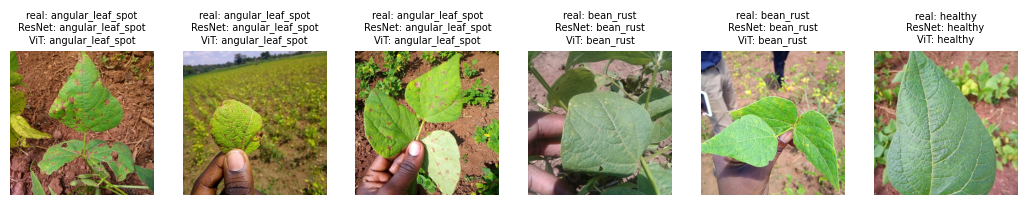

In [ ]:
# Predicciones de los dos modelos sobre imágenes de prueba
fig, axes = plt.subplots(1, 6, figsize=(13, 3))
for k, ax in enumerate(axes):
    ej = ds["test"][k * 20]
    preds = []
    for model, processor in [(resnet_hf, resnet_proc), (vit_hf, vit_proc)]:
        model.eval()
        with torch.no_grad():
            entrada = {kk: v.to(device) for kk, v in processor(ej["image"].convert("RGB"), return_tensors="pt").items()}
            preds.append(etiquetas[model(**entrada).logits.argmax(-1).item()])
    ax.imshow(ej["image"]); ax.axis("off")
    ax.set_title(f"real: {etiquetas[ej['labels']]}\nResNet: {preds[0]}\nViT: {preds[1]}", fontsize=7)
plt.show()

**Qué observar:**

- Con la cabeza al azar los dos modelos están en el nivel del azar (~1/3). Con solo entrenar la cabeza ya suben mucho: las representaciones aprendidas en ImageNet sirven para hojas de frijol aunque ninguna de las dos redes las vio nunca.
- El fine-tuning completo con tasa de aprendizaje baja suele llevarlos por encima del 90–95 %. Prueben `lr_todo=1e-3` y vean el *catastrophic forgetting* en acción.
- `ajustar` es, línea por línea, lo mismo que hicimos en la sección 2 con nuestro `SAE_model` y en la sección 5 con ResNet18: `requires_grad` para decidir qué se congela, y qué parámetros recibe el optimizador. Cambia el modelo y la escala del preentrenamiento, no la idea.

**Para guardar y compartir un modelo**: `model.save_pretrained("mi-modelo")` y `processor.save_pretrained("mi-modelo")`; con una cuenta de Hugging Face, `model.push_to_hub("usuario/mi-modelo")` lo publica para que cualquiera lo cargue con `from_pretrained`.

# 7. Cierre: de 2006 a hoy

| | Stacked autoencoder (2006) | Preentrenamiento auto-supervisado actual |
|---|---|---|
| Tarea de preentrenamiento | reconstruir la entrada, capa por capa | reconstruir partes enmascaradas de la entrada (BERT: palabras; MAE: parches de imagen), toda la red a la vez |
| Por qué capa por capa | no se podía entrenar una red profunda de una vez | ya se puede (ReLU, He, batch norm, residuales, Adam) |
| Datos de preentrenamiento | miles de imágenes | millones a miles de millones de ejemplos |
| Después | fine-tuning con etiquetas | fine-tuning con etiquetas (secciones 5 y 6), o uso directo |

Por eso hoy nadie preentrena *greedy* capa por capa, y a la vez **todo el mundo preentrena sin etiquetas y luego ajusta**: el *Masked Autoencoder* de He et al. (2022) es, literalmente, un autoencoder que aprende a reconstruir los parches de la imagen que se le taparon (un ViT como el de la sección 6.3, preentrenado como autoencoder), y las redes que acabamos de ajustar en la sección 6 se usan de la misma manera que nuestro `SAE_model` de la sección 2. Lo que cambió es la escala y las herramientas, no la idea.

## Ejercicios propuestos

1. En la sección 2, cambien `num_train_samples` del `labeled_loader` a 300 y a 6000. Cómo cambia la ventaja del preentrenamiento?
2. Conviertan `pretrain_layer` en un *stacked denoising autoencoder*: agreguen ruido gaussiano a la entrada de cada capa y reconstruyan la entrada limpia. Mejora la fase A?
3. En la sección 6, hagan fine-tuning con `lr=1e-3` en la fase B y comparen con `2e-5`. Qué pasa con la exactitud de validación?
4. Reemplacen `beans` por un dataset propio (una carpeta por clase, `load_dataset("imagefolder", data_dir=...)`) y repitan la sección 6.